In [1]:
#Imports 
import os
import sys
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F

from PIL import Image

from datasets import load_dataset

from transformers import (
    Sam2Model,
    Sam2Processor,
)

from torchvision import transforms

from tqdm.auto import tqdm

In [2]:

#Paths registry 
PROJECT_ROOT = Path("/home/zahranadeem/thesis")

MODEL_NAME = "facebook/sam2.1-hiera-tiny"

###############################################

AGRICLIP_ROOT = (
    PROJECT_ROOT
    / "agriclip_sam2"
    / "AgriCLIP"
)

ALIGNMENT_DIR = (
    AGRICLIP_ROOT
    / "AgriCLIP_alignment"
)

ALIGNER_PATH = (
    PROJECT_ROOT
    / "vegann_aligner.pth"
)

SAM2_CHECKPOINT = (
    PROJECT_ROOT
    / "sam2_vegann_checkpoints"
    / "best_sam2_vegann_mask_decoder.pt"
)

OUTPUT_DIR = (
    PROJECT_ROOT
    / "results"
    / "agriclip_attention_guided_sam2"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

print("Project:", PROJECT_ROOT)
print("AgriCLIP:", AGRICLIP_ROOT)
print("Aligner:", ALIGNER_PATH)
print("SAM2:", SAM2_CHECKPOINT)


Project: /home/zahranadeem/thesis
AgriCLIP: /home/zahranadeem/thesis/agriclip_sam2/AgriCLIP
Aligner: /home/zahranadeem/thesis/vegann_aligner.pth
SAM2: /home/zahranadeem/thesis/sam2_vegann_checkpoints/best_sam2_vegann_mask_decoder.pt


In [3]:
#Checking the device 
device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print(device)

cuda


In [4]:
#Loading VegAnn and split 
vegann = load_dataset(
    "simonMadec/VegAnn"
)

split = vegann["train"].train_test_split(
    test_size=0.20,
    seed=42
)

train_hf = split["train"]
val_hf = split["test"]

print(len(train_hf))
print(len(val_hf))

3020
755


In [5]:
#Detecting image and mask coloums 
columns = vegann["train"].column_names

IMAGE_KEY = next(
    x
    for x in columns
    if x in ["image", "images", "rgb"]
)

MASK_KEY = next(
    x
    for x in columns
    if x in [
        "mask",
        "masks",
        "label",
        "labels",
        "segmentation_mask",
    ]
)

print(IMAGE_KEY)
print(MASK_KEY)

image
mask


In [6]:
#Image helper
def get_image(index, split=val_hf):

    sample = split[index]

    image = sample[IMAGE_KEY]

    if not isinstance(image, Image.Image):
        image = Image.fromarray(np.array(image))

    return image.convert("RGB")


def get_mask(index, split=val_hf):

    sample = split[index]

    mask = np.array(sample[MASK_KEY])

    mask = (mask > 0).astype(np.uint8)

    return mask

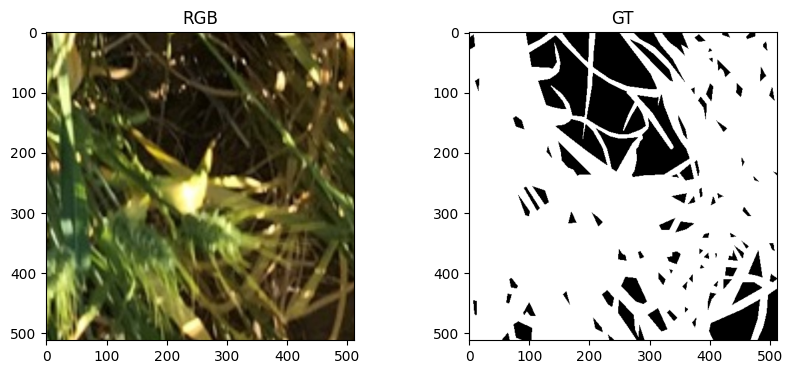

In [7]:
#Visualize image and mask 
image = get_image(0)
mask = get_mask(0)

plt.figure(figsize=(10,4))

plt.subplot(121)
plt.imshow(image)
plt.title("RGB")

plt.subplot(122)
plt.imshow(mask,cmap="gray")
plt.title("GT")

plt.show()

In [8]:
#Transform the image 
IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406,
]

IMAGENET_STD = [
    0.229,
    0.224,
    0.225,
]

dino_transform = transforms.Compose([

    transforms.Resize(
        (224,224)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        IMAGENET_MEAN,
        IMAGENET_STD,
    ),
])

In [9]:
#Load DINO 
dino_model = torch.hub.load(
    "facebookresearch/dino:main",
    "dino_resnet50",
    pretrained=True,
)

dino_model.eval()
dino_model.to(device)

for parameter in dino_model.parameters():
    parameter.requires_grad = False

print("DINO loaded.")

Using cache found in /home/zahranadeem/.cache/torch/hub/facebookresearch_dino_main
/home/zahranadeem/thesis/agriclip_sam2/agriclip_env/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/zahranadeem/thesis/agriclip_sam2/agriclip_env/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


DINO loaded.


In [10]:
import sys

ALIGNMENT_DIR = "/home/zahranadeem/thesis/agriclip_sam2/AgriCLIP/AgriCLIP_alignment"

if ALIGNMENT_DIR not in sys.path:
    sys.path.append(ALIGNMENT_DIR)

from TextToConcept import TextToConcept
from LinearAligner import LinearAligner

print("Imported successfully")

Imported successfully


In [11]:
text_to_concept = TextToConcept(
    dino_model,
    "dino_resnet50",
)

text_to_concept.load_linear_aligner(
    str(ALIGNER_PATH)
)

aligner = text_to_concept.linear_aligner

print("VegAnn aligner loaded.")
print("W shape:", tuple(aligner.W.shape))
print("b shape:", tuple(aligner.b.shape))

VegAnn aligner loaded.
W shape: (512, 2048)
b shape: (512,)


In [12]:
#Register a hook on Dino layer4
captured_feature_map = None


def capture_layer4_output(module, inputs, output):
    global captured_feature_map
    captured_feature_map = output.detach()


hook_handle = dino_model.layer4.register_forward_hook(
    capture_layer4_output
)

print("DINO layer4 hook registered.")

DINO layer4 hook registered.


In [13]:
#Extract spatial DINO descriptors automatically wheter 7x7 or other
@torch.no_grad()
def extract_dino_patch_features(pil_image):
    
    

    global captured_feature_map

    captured_feature_map = None

    image_tensor = dino_transform(
        pil_image
    ).unsqueeze(0).to(device)

    _ = dino_model(image_tensor)

    if captured_feature_map is None:
        raise RuntimeError(
            "The layer4 hook did not capture a feature map."
        )

    if captured_feature_map.ndim != 4:
        raise RuntimeError(
            "Expected feature map shape (B, C, H, W), "
            f"but received {captured_feature_map.shape}."
        )

    _, channels, grid_h, grid_w = captured_feature_map.shape

    patch_features = (
        captured_feature_map[0]
        .permute(1, 2, 0)
        .reshape(grid_h * grid_w, channels)
        .contiguous()
    )

    return patch_features, grid_h, grid_w

In [14]:
#Extract patches 
sample_index = 0

image = get_image(
    sample_index,
    split=val_hf,
)

gt_mask = get_mask(
    sample_index,
    split=val_hf,
)

patch_features, grid_h, grid_w = extract_dino_patch_features(
    image
)

print("Image size:", image.size)
print("Feature grid:", grid_h, "x", grid_w)
print("Patch features:", patch_features.shape)

Image size: (512, 512)
Feature grid: 7 x 7
Patch features: torch.Size([49, 2048])


In [15]:
print(
    "DINO feature dim:",
    patch_features.shape
)

print(
    "Aligner input:",
    aligner.W.shape
)

DINO feature dim: torch.Size([49, 2048])
Aligner input: torch.Size([512, 2048])


In [16]:
#Project patches using VegAnn aligner 
#Better to project first and then normalize in a shared concept space
@torch.no_grad()
def align_patch_features(patch_features):
    patch_features = patch_features.float().to(device)

    aligned_features = aligner.get_aligned_representation(
        patch_features
    )

    aligned_features = F.normalize(
        aligned_features,
        dim=1,
    )

    return aligned_features


aligned_patch_features = align_patch_features(
    patch_features
)

print("Aligned patch features:", aligned_patch_features.shape)

Aligned patch features: torch.Size([49, 512])


In [17]:
# ============================================================
# PROMPT STRATEGY 2 — SIMPLE VEGETATION PROMPTS
# ============================================================

"""VEGETATION_PROMPTS = [

    "vegetation",

    "green vegetation",

    "crop vegetation",

    "plants",

    "green plants",

    "crop plants",

    "agricultural vegetation",

    "vegetated field",
]

print("Prompt strategy: SIMPLE")
print("Number of prompts:", len(VEGETATION_PROMPTS))

for i, prompt in enumerate(VEGETATION_PROMPTS, 1):
    print(f"{i}. {prompt}") """
    
    

# ============================================================
# PPOSITIVE / NEGATIVE
# ============================================================

POSITIVE_PROMPTS = [

    "vegetation",
    "green vegetation",
    "crop plants",
    "crop vegetation",
    "agricultural plants",
    "green plants",
]

NEGATIVE_PROMPTS = [

    "soil",
    "bare soil",
    "ground",
    "bare ground",
    "non-vegetated ground",
    "agricultural soil",
]

print("Prompt strategy: POSITIVE / NEGATIVE")

print("\nPositive prompts:")
for i, prompt in enumerate(POSITIVE_PROMPTS, 1):
    print(f"{i}. {prompt}")

print("\nNegative prompts:")
for i, prompt in enumerate(NEGATIVE_PROMPTS, 1):
    print(f"{i}. {prompt}")
    
    
    


Prompt strategy: POSITIVE / NEGATIVE

Positive prompts:
1. vegetation
2. green vegetation
3. crop plants
4. crop vegetation
5. agricultural plants
6. green plants

Negative prompts:
1. soil
2. bare soil
3. ground
4. bare ground
5. non-vegetated ground
6. agricultural soil


In [18]:
#Encode and average vegetation prompts 
"""@torch.no_grad()
def encode_prompt_set(prompts):
    embeddings = []

    for prompt in prompts:
        embedding = text_to_concept.encode_text(
            [[prompt]]
        )

        if isinstance(embedding, np.ndarray):
            embedding = torch.from_numpy(embedding)

        if not torch.is_tensor(embedding):
            raise TypeError(
                "encode_text returned an unsupported type: "
                f"{type(embedding)}"
            )

        embedding = (
            embedding
            .detach()
            .float()
            .to(device)
            .reshape(-1)
        )

        embeddings.append(embedding)

    embeddings = torch.stack(
        embeddings,
        dim=0,
    )

    embeddings = F.normalize(
        embeddings,
        dim=1,
    )

    mean_embedding = embeddings.mean(
        dim=0,
    )

    mean_embedding = F.normalize(
        mean_embedding,
        dim=0,
    )

    return embeddings, mean_embedding


vegetation_text_embeddings, vegetation_embedding = encode_prompt_set(
    VEGETATION_PROMPTS
)

print(
    "Individual text embeddings:",
    vegetation_text_embeddings.shape,
)

print(
    "Mean vegetation embedding:",
    vegetation_embedding.shape,
) """


# ============================================================
# ENCODE POSITIVE AND NEGATIVE PROMPT SETS
# ============================================================

@torch.no_grad()
def encode_prompt_set(prompts):

    embeddings = []

    for prompt in prompts:

        embedding = text_to_concept.encode_text(
            [[prompt]]
        )

        if isinstance(embedding, np.ndarray):
            embedding = torch.from_numpy(
                embedding
            )

        if not torch.is_tensor(embedding):
            raise TypeError(
                "encode_text returned an unsupported type: "
                f"{type(embedding)}"
            )

        embedding = (
            embedding
            .detach()
            .float()
            .to(device)
            .reshape(-1)
        )

        embeddings.append(
            embedding
        )

    embeddings = torch.stack(
        embeddings,
        dim=0
    )

    # Normalize each prompt independently
    embeddings = F.normalize(
        embeddings,
        dim=1
    )

    # Average prompts
    mean_embedding = embeddings.mean(
        dim=0
    )

    # Normalize the averaged embedding
    mean_embedding = F.normalize(
        mean_embedding,
        dim=0
    )

    return embeddings, mean_embedding


# ------------------------------------------------------------
# POSITIVE
# ------------------------------------------------------------

positive_text_embeddings, positive_embedding = (
    encode_prompt_set(
        POSITIVE_PROMPTS
    )
)


# ------------------------------------------------------------
# NEGATIVE
# ------------------------------------------------------------

negative_text_embeddings, negative_embedding = (
    encode_prompt_set(
        NEGATIVE_PROMPTS
    )
)


print(
    "Positive embeddings:",
    positive_text_embeddings.shape
)

print(
    "Negative embeddings:",
    negative_text_embeddings.shape
)

print(
    "Positive mean embedding:",
    positive_embedding.shape
)

print(
    "Negative mean embedding:",
    negative_embedding.shape
)

Positive embeddings: torch.Size([6, 512])
Negative embeddings: torch.Size([6, 512])
Positive mean embedding: torch.Size([512])
Negative mean embedding: torch.Size([512])


In [19]:
# ============================================================
# POSITIVE - NEGATIVE CONCEPT
# ============================================================

vegetation_embedding = (
    positive_embedding
    - negative_embedding
)

vegetation_embedding = F.normalize(
    vegetation_embedding,
    dim=0
)

print(
    "Final vegetation embedding:",
    vegetation_embedding.shape
)

Final vegetation embedding: torch.Size([512])


In [20]:
import sys
from pathlib import Path

ALIGNMENT_DIR = Path(
    "/home/zahranadeem/thesis/agriclip_sam2/AgriCLIP/AgriCLIP_alignment"
)

if str(ALIGNMENT_DIR) not in sys.path:
    sys.path.insert(0, str(ALIGNMENT_DIR))

print(sys.path[0])

/usr/lib/python310.zip


In [21]:
from TextToConcept import TextToConcept
from LinearAligner import LinearAligner

print("Imported successfully")

Imported successfully


In [22]:
print(type(text_to_concept))
print(text_to_concept.__dict__.keys())

<class 'TextToConcept.TextToConcept'>
dict_keys(['model', 'model_name', 'device', 'clip_model', 'saved_dsets', 'linear_aligner'])


In [23]:
print(hasattr(text_to_concept, "tokenizer"))
print(hasattr(text_to_concept, "model"))

if hasattr(text_to_concept, "tokenizer"):
    print(type(text_to_concept.tokenizer))

if hasattr(text_to_concept, "model"):
    print(type(text_to_concept.model))

False
True
<class 'torchvision.models.resnet.ResNet'>


In [24]:
# Compute AgriCLIP patch-text similarity scores

with torch.no_grad():

    patch_scores = (
        aligned_patch_features 
        @ vegetation_embedding
    )

print("Patch scores shape:", patch_scores.shape)
print("Min:", patch_scores.min().item())
print("Max:", patch_scores.max().item())

Patch scores shape: torch.Size([49])
Min: -0.020329272374510765
Max: 0.14176683127880096


In [25]:
TOP_K =  49
scores = patch_scores.cpu().numpy()

sorted_indices = np.argsort(scores)[::-1]

topk_indices = sorted_indices[:TOP_K]

print("Top-K patch indices:")
print(topk_indices)

print("Scores:")
print(scores[topk_indices])

Top-K patch indices:
[13 43  6 20 29 10  1 47 18  8 46 22 19  2  3 26 17 36 34 33 23 35 40 15
 30 12 21  7 14 41 11 28 44  9 25  4 42 27 48 16 24  0 32  5 31 38 37 39
 45]
Scores:
[ 0.14176683  0.1323612   0.13027082  0.12215064  0.12186894  0.12176584
  0.1201911   0.1149954   0.11485691  0.11447184  0.11091828  0.10906088
  0.10504849  0.10468902  0.10449479  0.10404819  0.10284875  0.10084666
  0.09749009  0.09741492  0.09656537  0.09646869  0.09443323  0.09212168
  0.09189506  0.09112763  0.09039424  0.0843125   0.08208122  0.07708293
  0.07664943  0.07642687  0.0741242   0.07355249  0.07166357  0.07080624
  0.07058705  0.07019228  0.05853003  0.05453878  0.04894566  0.04602269
  0.04340003  0.04099484  0.04041386  0.03434183  0.03266831  0.01419109
 -0.02032927]


In [26]:
PATCH_ROWS = 7
PATCH_COLS = 7

H, W = image.size[1], image.size[0]

patch_h = H / PATCH_ROWS
patch_w = W / PATCH_COLS

boxes = []

for idx in topk_indices:

    r = idx // PATCH_COLS
    c = idx % PATCH_COLS

    x1 = int(c * patch_w)
    y1 = int(r * patch_h)

    x2 = int((c + 1) * patch_w)
    y2 = int((r + 1) * patch_h)

    boxes.append([x1, y1, x2, y2])

boxes = np.array(boxes)

print(boxes)

[[438  73 512 146]
 [ 73 438 146 512]
 [438   0 512  73]
 [438 146 512 219]
 [ 73 292 146 365]
 [219  73 292 146]
 [ 73   0 146  73]
 [365 438 438 512]
 [292 146 365 219]
 [ 73  73 146 146]
 [292 438 365 512]
 [ 73 219 146 292]
 [365 146 438 219]
 [146   0 219  73]
 [219   0 292  73]
 [365 219 438 292]
 [219 146 292 219]
 [ 73 365 146 438]
 [438 292 512 365]
 [365 292 438 365]
 [146 219 219 292]
 [  0 365  73 438]
 [365 365 438 438]
 [ 73 146 146 219]
 [146 292 219 365]
 [365  73 438 146]
 [  0 219  73 292]
 [  0  73  73 146]
 [  0 146  73 219]
 [438 365 512 438]
 [292  73 365 146]
 [  0 292  73 365]
 [146 438 219 512]
 [146  73 219 146]
 [292 219 365 292]
 [292   0 365  73]
 [  0 438  73 512]
 [438 219 512 292]
 [438 438 512 512]
 [146 146 219 219]
 [219 219 292 292]
 [  0   0  73  73]
 [292 292 365 365]
 [365   0 438  73]
 [219 292 292 365]
 [219 365 292 438]
 [146 365 219 438]
 [292 365 365 438]
 [219 438 292 512]]


In [27]:
xmin = boxes[:,0].min()
ymin = boxes[:,1].min()

xmax = boxes[:,2].max()
ymax = boxes[:,3].max()

merged_box = np.array(
    [
        xmin,
        ymin,
        xmax,
        ymax
    ],
    dtype=np.int32
)

print(merged_box)

[  0   0 512 512]


In [28]:
margin = 25

xmin = max(0, xmin - margin)
ymin = max(0, ymin - margin)

xmax = min(W-1, xmax + margin)
ymax = min(H-1, ymax + margin)

merged_box = np.array(
    [
        xmin,
        ymin,
        xmax,
        ymax
    ]
)

print(merged_box)

[  0   0 511 511]


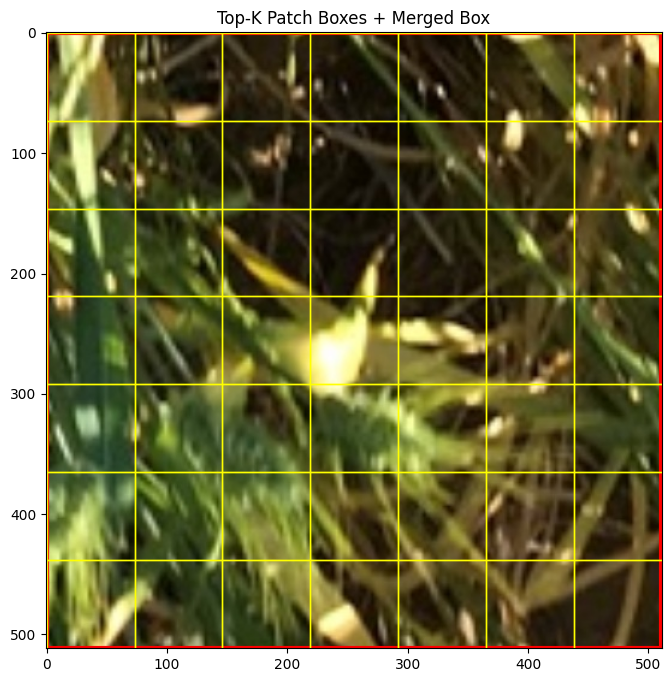

In [29]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

fig, ax = plt.subplots(figsize=(8,8))

ax.imshow(image)

rect = patches.Rectangle(

    (merged_box[0], merged_box[1]),

    merged_box[2]-merged_box[0],

    merged_box[3]-merged_box[1],

    linewidth=3,

    edgecolor="red",

    facecolor="none",

)

ax.add_patch(rect)

for b in boxes:

    rect = patches.Rectangle(

        (b[0], b[1]),

        b[2]-b[0],

        b[3]-b[1],

        linewidth=1,

        edgecolor="yellow",

        facecolor="none",

    )

    ax.add_patch(rect)

plt.title("Top-K Patch Boxes + Merged Box")

plt.show()

In [30]:
print("Merged Box:", merged_box)

print("Image size:", image.size)

print("GT foreground:", gt_mask.sum())

Merged Box: [  0   0 511 511]
Image size: (512, 512)
GT foreground: 208628


In [31]:
#Load fine tuned SAM2 model 
sam2_processor = Sam2Processor.from_pretrained(
    MODEL_NAME
)

sam2_model = Sam2Model.from_pretrained(
    MODEL_NAME
)

sam2_checkpoint = torch.load(
    SAM2_CHECKPOINT,
    map_location="cpu",
)

print("SAM2 checkpoint type:", type(sam2_checkpoint))

if (
    isinstance(sam2_checkpoint, dict)
    and "mask_decoder_state_dict" in sam2_checkpoint
):
    mask_decoder_state_dict = sam2_checkpoint[
        "mask_decoder_state_dict"
    ]
elif isinstance(sam2_checkpoint, dict):
    # Supports a checkpoint that directly contains decoder weights.
    mask_decoder_state_dict = sam2_checkpoint
else:
    raise TypeError(
        "Unsupported SAM2 checkpoint structure."
    )

load_result = sam2_model.mask_decoder.load_state_dict(
    mask_decoder_state_dict,
    strict=True,
)

sam2_model = sam2_model.to(device)
sam2_model.eval()

print("Fine-tuned SAM2 mask decoder loaded.")
print(load_result)

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

SAM2 checkpoint type: <class 'dict'>
Fine-tuned SAM2 mask decoder loaded.
<All keys matched successfully>


In [32]:
checkpoint = torch.load(
    SAM2_CHECKPOINT,
    map_location=device
)

print(checkpoint.keys())

dict_keys(['epoch', 'model_name', 'mask_decoder_state_dict', 'optimizer_state_dict', 'best_mean_iou', 'history'])


In [33]:
sam2_inputs = sam2_processor(

    images=image,

    input_boxes=[[merged_box]],
    #input_boxes = [[gt_box]],

    return_tensors="pt",

)

sam2_inputs = {

    k: v.to(device)

    if torch.is_tensor(v)

    else v

    for k, v in sam2_inputs.items()

}

with torch.no_grad():

    sam2_outputs = sam2_model(
        **sam2_inputs
    )

print(sam2_outputs.pred_masks.shape)
print(sam2_outputs.iou_scores.shape)

torch.Size([1, 1, 3, 256, 256])
torch.Size([1, 1, 3])


In [34]:
# Pick best candidate

best_index = sam2_outputs.iou_scores[0,0].argmax()

print("Best candidate:", best_index.item())

# Raw logits

best_logits = sam2_outputs.pred_masks[
    0,
    0,
    best_index
]

print(best_logits.shape)

# Convert to probability

best_mask_probability = torch.sigmoid(best_logits)

# Resize to original image size

best_mask_probability = torch.nn.functional.interpolate(

    best_mask_probability.unsqueeze(0).unsqueeze(0),

    size=gt_mask.shape,

    mode="bilinear",

    align_corners=False,

).squeeze()

best_mask = (

    best_mask_probability > 0.15

).cpu().numpy().astype(np.uint8)

print(best_mask.shape)

Best candidate: 2
torch.Size([256, 256])
(512, 512)


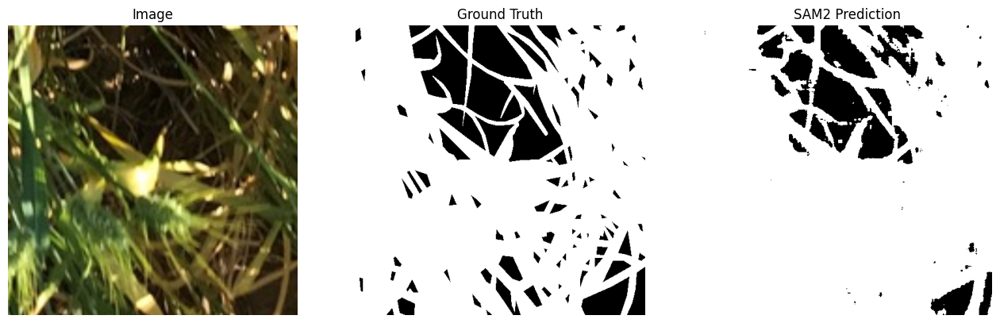

In [35]:
plt.figure(figsize=(16,5))

plt.subplot(131)
plt.imshow(image)
plt.title("Image")
plt.axis("off")

plt.subplot(132)
plt.imshow(gt_mask,cmap="gray")
plt.title("Ground Truth")
plt.axis("off")

plt.subplot(133)
plt.imshow(best_mask,cmap="gray")
plt.title("SAM2 Prediction")
plt.axis("off")

plt.show()

In [36]:
#Select and decode the best SAM2 candidate 
best_candidate_index = int(
    sam2_outputs.iou_scores[0, 0]
    .argmax()
    .item()
)

best_mask_logits = sam2_outputs.pred_masks[
    0,
    0,
    best_candidate_index,
]

best_mask_probability = torch.sigmoid(
    best_mask_logits
)

original_height = int(
    sam2_inputs["original_sizes"][0, 0].item()
)
original_width = int(
    sam2_inputs["original_sizes"][0, 1].item()
)

best_mask_probability = F.interpolate(
    best_mask_probability[None, None],
    size=(original_height, original_width),
    mode="bilinear",
    align_corners=False,
)[0, 0]

pred_mask = (
    best_mask_probability >= 0.5
).detach().cpu().numpy().astype(np.uint8)

print("Selected SAM2 candidate:", best_candidate_index)
print(
    "Predicted IoU confidence:",
    float(
        sam2_outputs.iou_scores[
            0,
            0,
            best_candidate_index,
        ].item()
    ),
)
print("Prediction shape:", pred_mask.shape)
print("Foreground pixels:", int(pred_mask.sum()))

Selected SAM2 candidate: 2
Predicted IoU confidence: 0.9524438381195068
Prediction shape: (512, 512)
Foreground pixels: 208917


Min : 2.7819598e-05
Max : 0.99997604
Mean: 0.7812024
Std : 0.34581533


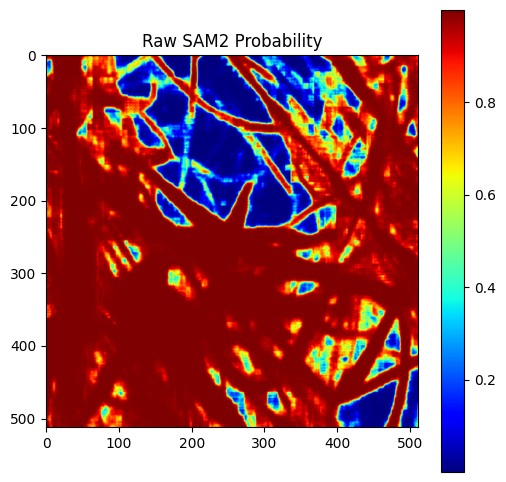

In [37]:
# Visualize raw SAM2 probability

prob = best_mask_probability.detach().cpu().numpy()

print("Min :", prob.min())
print("Max :", prob.max())
print("Mean:", prob.mean())
print("Std :", prob.std())

plt.figure(figsize=(6,6))
plt.imshow(prob, cmap="jet")
plt.colorbar()
plt.title("Raw SAM2 Probability")
plt.show()

In [38]:
#Define segmentation metrics 
def compute_binary_metrics(prediction, ground_truth):
    prediction = prediction.astype(bool)
    ground_truth = ground_truth.astype(bool)

    intersection = np.logical_and(
        prediction,
        ground_truth,
    ).sum()

    union = np.logical_or(
        prediction,
        ground_truth,
    ).sum()

    pred_pixels = prediction.sum()
    gt_pixels = ground_truth.sum()

    iou = (
        intersection / union
        if union > 0
        else 1.0
    )

    dice_denominator = pred_pixels + gt_pixels

    dice = (
        2.0 * intersection / dice_denominator
        if dice_denominator > 0
        else 1.0
    )

    precision = (
        intersection / pred_pixels
        if pred_pixels > 0
        else 0.0
    )

    recall = (
        intersection / gt_pixels
        if gt_pixels > 0
        else 0.0
    )

    return {
        "iou": float(iou),
        "dice": float(dice),
        "precision": float(precision),
        "recall": float(recall),
        "intersection": int(intersection),
        "union": int(union),
        "pred_pixels": int(pred_pixels),
        "gt_pixels": int(gt_pixels),
    }


metrics = compute_binary_metrics(
    pred_mask,
    gt_mask,
)

for name, value in metrics.items():
    if isinstance(value, float):
        print(f"{name:>14}: {value:.4f}")
    else:
        print(f"{name:>14}: {value}")

           iou: 0.9022
          dice: 0.9486
     precision: 0.9479
        recall: 0.9492
  intersection: 198036
         union: 219509
   pred_pixels: 208917
     gt_pixels: 208628


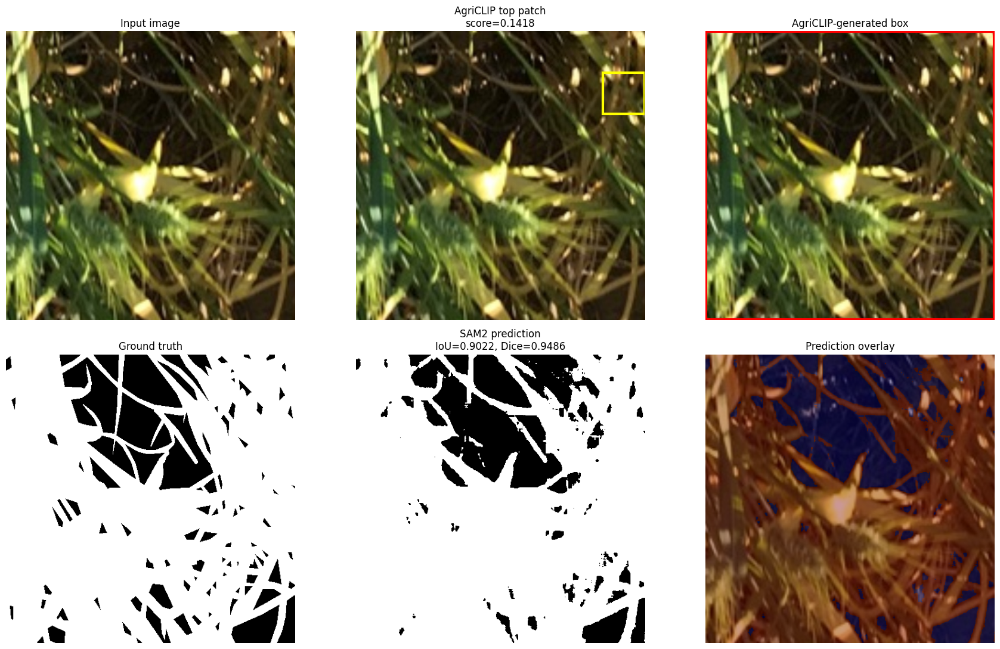

In [39]:
# Visualize the complete result

fig, ax = plt.subplots(
    2,
    3,
    figsize=(18, 11),
)

# Image
ax[0, 0].imshow(image)
ax[0, 0].set_title("Input image")
ax[0, 0].axis("off")



# Winning patch
best_patch = boxes[0]

ax[0, 1].imshow(image)

ax[0, 1].add_patch(
    plt.Rectangle(
        (best_patch[0], best_patch[1]),
        best_patch[2] - best_patch[0],
        best_patch[3] - best_patch[1],
        fill=False,
        edgecolor="yellow",
        linewidth=3,
    )
)

ax[0, 1].set_title(
    f"AgriCLIP top patch\nscore={scores[topk_indices[0]]:.4f}"
)

ax[0, 1].axis("off")


# Expanded AgriCLIP box
ax[0, 2].imshow(image)

ax[0, 2].add_patch(
    plt.Rectangle(
        (merged_box[0], merged_box[1]),
        merged_box[2] - merged_box[0],
        merged_box[3] - merged_box[1],
        fill=False,
        edgecolor="red",
        linewidth=3,
    )
)

ax[0, 2].set_title(
    "AgriCLIP-generated box"
)

ax[0, 2].axis("off")


# Ground truth
ax[1, 0].imshow(
    gt_mask,
    cmap="gray",
)

ax[1, 0].set_title(
    "Ground truth"
)

ax[1, 0].axis("off")


# Prediction
ax[1, 1].imshow(
    pred_mask,
    cmap="gray",
)

ax[1, 1].set_title(
    f"SAM2 prediction\n"
    f"IoU={metrics['iou']:.4f}, "
    f"Dice={metrics['dice']:.4f}"
)

ax[1, 1].axis("off")


# Overlay
ax[1, 2].imshow(image)

ax[1, 2].imshow(
    pred_mask,
    cmap="jet",
    alpha=0.40,
)

ax[1, 2].set_title(
    "Prediction overlay"
)

ax[1, 2].axis("off")


plt.tight_layout()
plt.show()

In [40]:
#Replaces manual Top K code 
@torch.no_grad()
def generate_agriclip_box(
    image,
    top_k = 32

):

    # Extract DINO patches
    patch_features, grid_h, grid_w = extract_dino_patch_features(
        image
    )


    # Align to AgriCLIP space
    aligned_features = align_patch_features(
        patch_features
    )


    # Patch-text similarity
    patch_scores = (
        aligned_features 
        @ vegetation_embedding
    )


    scores = patch_scores.cpu().numpy()


    # Top-K patches
    topk_indices = np.argsort(scores)[::-1][:top_k]


    H, W = image.size[1], image.size[0]


    patch_h = H / grid_h
    patch_w = W / grid_w


    boxes = []


    for idx in topk_indices:

        r = idx // grid_w
        c = idx % grid_w


        x1 = int(c * patch_w)
        y1 = int(r * patch_h)

        x2 = int((c+1) * patch_w)
        y2 = int((r+1) * patch_h)


        boxes.append(
            [
                x1,
                y1,
                x2,
                y2
            ]
        )


    boxes = np.array(boxes)


    # Merge boxes
    xmin = boxes[:,0].min()
    ymin = boxes[:,1].min()

    xmax = boxes[:,2].max()
    ymax = boxes[:,3].max()


    margin = 25


    xmin = max(
        0,
        xmin-margin
    )

    ymin = max(
        0,
        ymin-margin
    )

    xmax = min(
        W-1,
        xmax+margin
    )

    ymax = min(
        H-1,
        ymax+margin
    )


    merged_box = np.array(
        [
            xmin,
            ymin,
            xmax,
            ymax
        ],
        dtype=np.int32
    )


    return (
        merged_box,
        boxes,
        scores,
        topk_indices
    )

In [41]:
#SAM2 prediction function 
@torch.no_grad()
def sam2_predict_box(
    image,
    box
):

    inputs = sam2_processor(
        images=image,
        input_boxes=[
            [
                box.tolist()
            ]
        ],
        return_tensors="pt",
    )


    inputs = {
        k:v.to(device)
        if torch.is_tensor(v)
        else v
        for k,v in inputs.items()
    }


    outputs = sam2_model(
        **inputs
    )


    # Best mask candidate

    best_idx = (
        outputs.iou_scores[0,0]
        .argmax()
        .item()
    )


    logits = outputs.pred_masks[
        0,
        0,
        best_idx
    ]


    probability = torch.sigmoid(
        logits
    )


    height = inputs["original_sizes"][0,0]
    width = inputs["original_sizes"][0,1]


    probability = F.interpolate(
        probability[None,None],
        size=(
            height,
            width
        ),
        mode="bilinear",
        align_corners=False,
    )[0,0]


    prediction = (
        probability > 0.5
    ).cpu().numpy().astype(np.uint8)


    confidence = (
        outputs.iou_scores[
            0,
            0,
            best_idx
        ]
        .item()
    )


    return prediction, confidence

In [42]:
import pandas as pd
from tqdm import tqdm

# Full validation loop
results = []
TOP_K = 32


for idx in tqdm(range(len(val_hf))):

    image = get_image(idx, split=val_hf)
    gt_mask = get_mask(idx, split=val_hf)

    try:
        # AgriCLIP localization
        agriclip_box, boxes, scores, topk_indices = generate_agriclip_box(
            image, TOP_K
        )

        # SAM2 segmentation
        pred_mask, confidence = sam2_predict_box(image, agriclip_box)

        # Metrics
        metrics = compute_binary_metrics(pred_mask, gt_mask)

        results.append(
            {
                "image_id": idx,
                "iou": metrics["iou"],
                "dice": metrics["dice"],
                "precision": metrics["precision"],
                "recall": metrics["recall"],
                "sam2_confidence": confidence,
            }
        )

    except Exception as e:
        print(f"Failed at image {idx}: {e}")
        raise e

print("\nFinished validation\n")

# ============================================================
# RESULTS AGGREGATION & PRINTING
# ============================================================
if len(results) > 0:
    results_df = pd.DataFrame(results)

    print("==================================================")
    print("           VALIDATION PERFORMANCE SUMMARY          ")
    print("==================================================")
    print(f"Total Evaluated Images:  {len(results_df)}")
    print(f"Mean Segmentation IoU:   {results_df['iou'].mean() * 100:.2f}%")
    print(f"Mean Dice Score:         {results_df['dice'].mean() * 100:.2f}%")
    print(f"Mean Precision:          {results_df['precision'].mean() * 100:.2f}%")
    print(f"Mean Recall:             {results_df['recall'].mean() * 100:.2f}%")
    print(f"Mean SAM2 Confidence:    {results_df['sam2_confidence'].mean():.4f}")
    print("==================================================")
else:
    print("No valid results computed.")


100%|██████████| 755/755 [00:31<00:00, 23.92it/s]


Finished validation

           VALIDATION PERFORMANCE SUMMARY          
Total Evaluated Images:  755
Mean Segmentation IoU:   84.03%
Mean Dice Score:         90.08%
Mean Precision:          89.01%
Mean Recall:             92.29%
Mean SAM2 Confidence:    0.9358


In [43]:
import matplotlib.pyplot as plt
import pandas as pd

# ============================================================
# K ABLATION RESULTS
# ============================================================

results = {
    "K": [4, 6, 8, 10, 12, 14, 16, 24, 32,49],
    
    "IoU": [
        71.13, 76.65, 79.72, 81.30, 82.25,
        82.69, 83.06, 83.87, 84.03,84.04
    ],
    
    "Dice": [
        80.86, 85.08, 87.26, 88.34, 89.00,
        89.25, 89.48, 89.98, 90.08, 90.09
    ],
    
    "Precision": [
        91.02, 90.59, 90.18, 89.88, 89.61,
        89.40, 89.27, 89.04, 89.01, 89.01
    ],
    
    "Recall": [
        75.66, 82.39, 86.28, 88.27, 89.64,
        90.37, 90.92, 92.06, 92.29,92.31
    ],
    
    "SAM2_Confidence": [
        0.9114, 0.9216, 0.9283, 0.9313, 0.9326,
        0.9337, 0.9339, 0.9359, 0.9358,0.9351
    ]
}

k_results = pd.DataFrame(results)

display(k_results)

,K,IoU,Dice,Precision,Recall,SAM2_Confidence
0,4,71.13,80.86,91.02,75.66,0.9114
1,6,76.65,85.08,90.59,82.39,0.9216
2,8,79.72,87.26,90.18,86.28,0.9283
3,10,81.30,88.34,89.88,88.27,0.9313
4,12,82.25,89.00,89.61,89.64,0.9326
5,14,82.69,89.25,89.40,90.37,0.9337
6,16,83.06,89.48,89.27,90.92,0.9339
7,24,83.87,89.98,89.04,92.06,0.9359
8,32,84.03,90.08,89.01,92.29,0.9358
9,49,84.04,90.09,89.01,92.31,0.9351


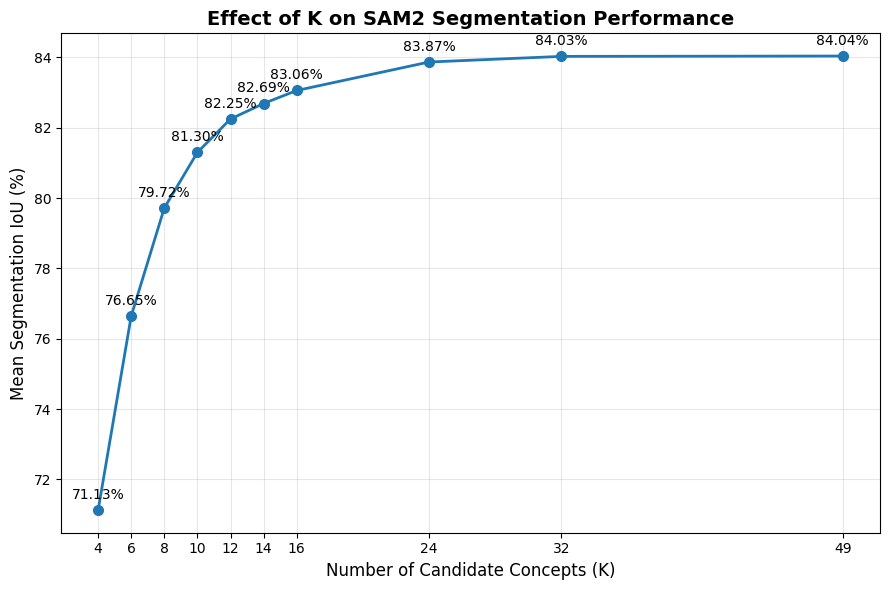

In [44]:
# ============================================================
# K vs IoU
# ============================================================

plt.figure(figsize=(9, 6))

plt.plot(
    k_results["K"],
    k_results["IoU"],
    marker="o",
    linewidth=2,
    markersize=7
)

# Add values above each point
for x, y in zip(k_results["K"], k_results["IoU"]):
    plt.annotate(
        f"{y:.2f}%",
        (x, y),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center"
    )

plt.xlabel("Number of Candidate Concepts (K)", fontsize=12)
plt.ylabel("Mean Segmentation IoU (%)", fontsize=12)

plt.title(
    "Effect of K on SAM2 Segmentation Performance",
    fontsize=14,
    fontweight="bold"
)

plt.xticks(k_results["K"])
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

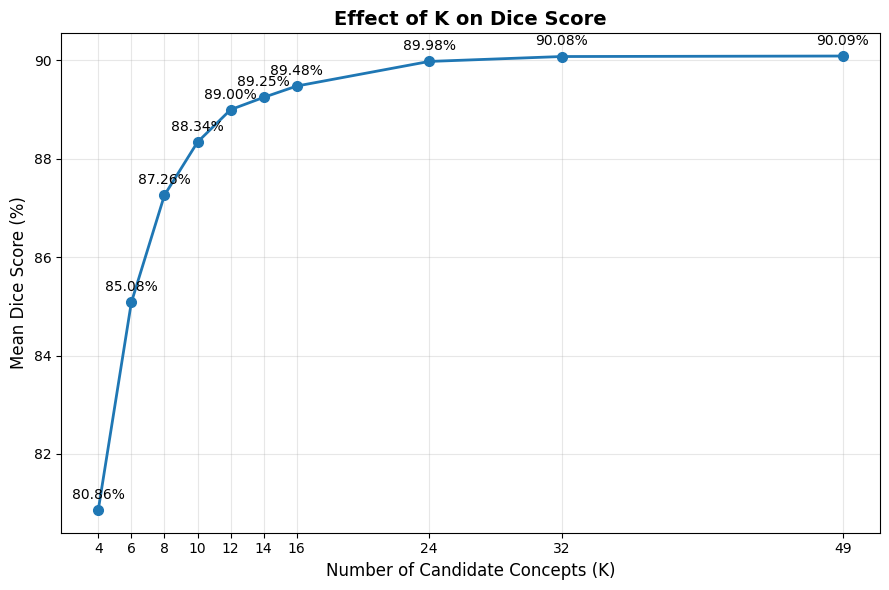

In [45]:
# ============================================================
# K vs Dice
# ============================================================

plt.figure(figsize=(9, 6))

plt.plot(
    k_results["K"],
    k_results["Dice"],
    marker="o",
    linewidth=2,
    markersize=7
)

for x, y in zip(k_results["K"], k_results["Dice"]):
    plt.annotate(
        f"{y:.2f}%",
        (x, y),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center"
    )

plt.xlabel("Number of Candidate Concepts (K)", fontsize=12)
plt.ylabel("Mean Dice Score (%)", fontsize=12)

plt.title(
    "Effect of K on Dice Score",
    fontsize=14,
    fontweight="bold"
)

plt.xticks(k_results["K"])
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

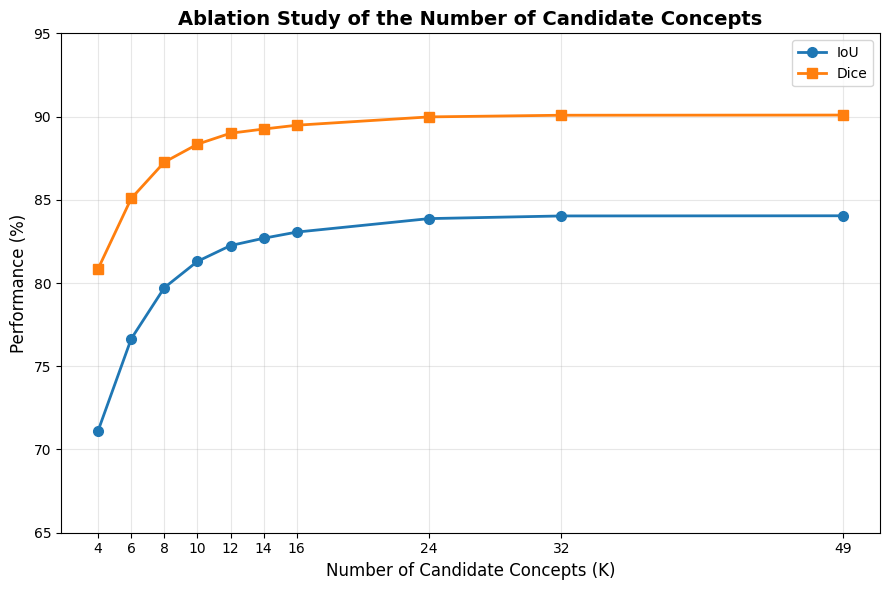

In [46]:
# ============================================================
# K vs IoU and Dice
# ============================================================

plt.figure(figsize=(9, 6))

plt.plot(
    k_results["K"],
    k_results["IoU"],
    marker="o",
    linewidth=2,
    markersize=7,
    label="IoU"
)

plt.plot(
    k_results["K"],
    k_results["Dice"],
    marker="s",
    linewidth=2,
    markersize=7,
    label="Dice"
)

plt.xlabel("Number of Candidate Concepts (K)", fontsize=12)
plt.ylabel("Performance (%)", fontsize=12)

plt.title(
    "Ablation Study of the Number of Candidate Concepts",
    fontsize=14,
    fontweight="bold"
)

plt.xticks(k_results["K"])
plt.ylim(65, 95)

plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

In [47]:
# ============================================================
# PROMPT ABLATION RESULTS
# ============================================================

prompt_results = pd.DataFrame({

    "Experiment": [
        "Original prompts",
        "Simple prompts",
        "Positive - Negative",
        "Visual Positive - Negative",
        "Agricultural Vegetation - Soil"
    ],

    "IoU": [
        75.85,
        77.31,
        79.72,
        78.93,
        78.35
    ],

    "Dice": [
        84.30,
        85.42,
        87.26,
        86.60,
        86.25
    ]
})

prompt_results

,Experiment,IoU,Dice
0,Original prompts,75.85,84.30
1,Simple prompts,77.31,85.42
2,Positive - Negative,79.72,87.26
3,Visual Positive - Negative,78.93,86.60
4,Agricultural Vegetation - Soil,78.35,86.25


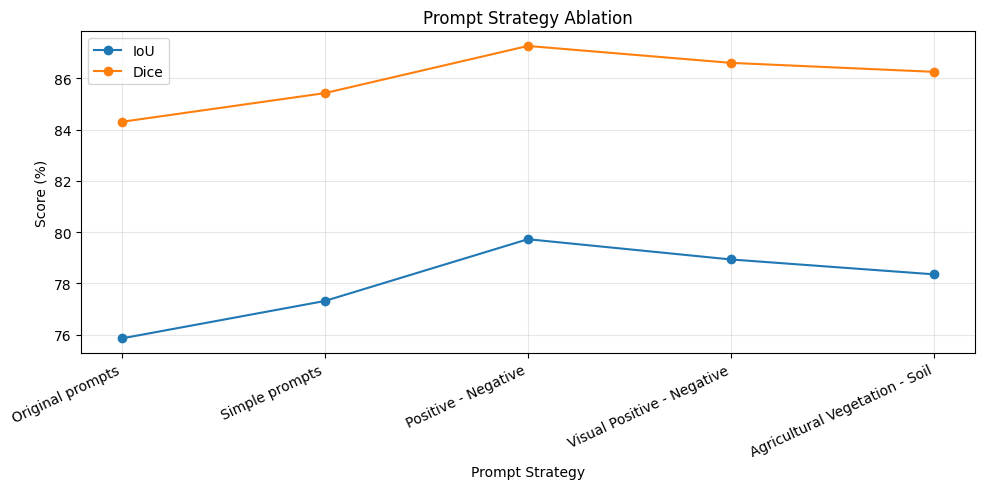

In [48]:
# ============================================================
# PROMPT ABLATION: IoU AND DICE
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

x = np.arange(len(prompt_results))

plt.plot(
    x,
    prompt_results["IoU"],
    marker="o",
    label="IoU"
)

plt.plot(
    x,
    prompt_results["Dice"],
    marker="o",
    label="Dice"
)

plt.xticks(
    x,
    prompt_results["Experiment"],
    rotation=25,
    ha="right"
)

plt.ylabel("Score (%)")
plt.xlabel("Prompt Strategy")
plt.title("Prompt Strategy Ablation")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Computational Cost

In [49]:


import time
import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm

print("Computational cost benchmarking tools loaded.")

Computational cost benchmarking tools loaded.


In [50]:


def synchronize_gpu():

    if torch.cuda.is_available():
        torch.cuda.synchronize()

In [51]:


print("PyTorch version:", torch.__version__)

print(
    "CUDA available:",
    torch.cuda.is_available()
)

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

    print(
        "CUDA version:",
        torch.version.cuda
    )

PyTorch version: 2.12.0+cu130
CUDA available: True
GPU: NVIDIA GeForce RTX 4090
CUDA version: 13.0


In [52]:
def benchmark_agriclip_box(samples, top_k=32, max_samples=50):

    runtimes = []

    # Limit maximum samples safely using dataset length
    num_to_test = min(max_samples, len(samples))

    print(
        f"Benchmarking AgriCLIP box generation "
        f"K={top_k} on {num_to_test} images..."
    )

    # Use a direct index loop matching your successful main validation loop
    for idx in tqdm(range(num_to_test)):
        try:
            # ----------------------------------------------------
            # Get image using your working helper function
            # ----------------------------------------------------
            image = get_image(idx, split=samples)

            if not isinstance(image, Image.Image):
                image = Image.fromarray(np.asarray(image))

            image = image.convert("RGB")

            # ----------------------------------------------------
            # GPU synchronization BEFORE timing
            # ----------------------------------------------------
            synchronize_gpu()

            start_time = time.perf_counter()

            # ----------------------------------------------------
            # YOUR EXISTING AGRICLIP BOX FUNCTION
            # ----------------------------------------------------
            result = generate_agriclip_box(image, top_k=top_k)

            # ----------------------------------------------------
            # GPU synchronization AFTER timing
            # ----------------------------------------------------
            synchronize_gpu()

            end_time = time.perf_counter()

            runtime = end_time - start_time
            runtimes.append(runtime)

        except Exception as e:
            print(f"Failed to benchmark index {idx}: {e}")
            continue

    runtimes = np.asarray(runtimes)

    return {
        "K": top_k,
        "images": len(runtimes),
        "mean_runtime_sec": float(np.mean(runtimes)),
        "std_runtime_sec": float(np.std(runtimes)),
        "min_runtime_sec": float(np.min(runtimes)),
        "max_runtime_sec": float(np.max(runtimes)),
        "images_per_sec": float(1.0 / np.mean(runtimes)),
    }


In [53]:
# ============================================================
# TEST AGRICLIP BOX RUNTIME — K=32
# ============================================================

runtime_k32 = benchmark_agriclip_box(
    samples=val_hf,
    top_k=32,
    max_samples=755
)

runtime_k32

Benchmarking AgriCLIP box generation K=32 on 755 images...


  0%|          | 0/755 [00:00<?, ?it/s]

{'K': 32,
 'images': 755,
 'mean_runtime_sec': 0.0035369301751404015,
 'std_runtime_sec': 0.000102249270483222,
 'min_runtime_sec': 0.0033768671564757824,
 'max_runtime_sec': 0.00602886313572526,
 'images_per_sec': 282.7310550342725}

In [54]:
#Benchmark all K values 


K_VALUES = [
    4,
    8,
    16,
    24,
    32,
    49
]

runtime_results = []

for k in K_VALUES:

    result = benchmark_agriclip_box(
        samples=val_hf,
        top_k=k,
        max_samples=755
    )

    runtime_results.append(
        result
    )

runtime_df = pd.DataFrame(
    runtime_results
)

runtime_df

Benchmarking AgriCLIP box generation K=4 on 755 images...


  0%|          | 0/755 [00:00<?, ?it/s]

Benchmarking AgriCLIP box generation K=8 on 755 images...


  0%|          | 0/755 [00:00<?, ?it/s]

Benchmarking AgriCLIP box generation K=16 on 755 images...


  0%|          | 0/755 [00:00<?, ?it/s]

... (3 outputs left out)

  0%|          | 0/755 [00:00<?, ?it/s]

Benchmarking AgriCLIP box generation K=49 on 755 images...


  0%|          | 0/755 [00:00<?, ?it/s]

,K,images,mean_runtime_sec,std_runtime_sec,min_runtime_sec,max_runtime_sec,images_per_sec
0,4,755,0.003571,0.000593,0.003292,0.008259,280.036894
1,8,755,0.003441,0.000049,0.003281,0.003818,290.618744
2,16,755,0.003532,0.001219,0.003314,0.036164,283.155928
3,24,755,0.003513,0.000126,0.003334,0.006103,284.678559
4,32,755,0.003609,0.000463,0.003367,0.009004,277.111843
5,49,755,0.003601,0.000364,0.003416,0.008435,277.702996


In [55]:
#Adding in milliseconds 


runtime_df["mean_runtime_ms"] = (
    runtime_df["mean_runtime_sec"] * 1000
)

runtime_df["std_runtime_ms"] = (
    runtime_df["std_runtime_sec"] * 1000
)

runtime_df[
    [
        "K",
        "mean_runtime_ms",
        "std_runtime_ms",
        "images_per_sec"
    ]
]

,K,mean_runtime_ms,std_runtime_ms,images_per_sec
0,4,3.570958,0.592579,280.036894
1,8,3.440934,0.049327,290.618744
2,16,3.531623,1.219036,283.155928
3,24,3.512734,0.126047,284.678559
4,32,3.608651,0.463046,277.111843
5,49,3.600969,0.363979,277.702996


In [56]:
# ============================================================
# K vs SEGMENTATION PERFORMANCE
# ============================================================

k_iou_results = pd.DataFrame({

    "K": [
        4,
        6,
        8,
        10,
        12,
        14,
        16,
        24,
        32,
        49
    ],

    "IoU": [
        71.13,
        76.65,
        79.72,
        81.30,
        82.25,
        82.69,
        83.06,
        83.87,
        84.03,
        84.04
    ],

    "Dice": [
        80.86,
        85.08,
        87.26,
        88.34,
        89.00,
        89.25,
        89.48,
        89.98,
        90.08,
        90.09
    ]
})

k_iou_results

,K,IoU,Dice
0,4,71.13,80.86
1,6,76.65,85.08
2,8,79.72,87.26
3,10,81.30,88.34
4,12,82.25,89.00
5,14,82.69,89.25
6,16,83.06,89.48
7,24,83.87,89.98
8,32,84.03,90.08
9,49,84.04,90.09


In [57]:
# ============================================================
# COMBINE ACCURACY + COMPUTATIONAL COST
# ============================================================

k_cost_results = pd.merge(
    k_iou_results,
    runtime_df[
        [
            "K",
            "mean_runtime_ms",
            "std_runtime_ms",
            "images_per_sec"
        ]
    ],
    on="K",
    how="left"
)

k_cost_results

,K,IoU,Dice,mean_runtime_ms,std_runtime_ms,images_per_sec
0,4,71.13,80.86,3.570958,0.592579,280.036894
1,6,76.65,85.08,NaN,NaN,NaN
2,8,79.72,87.26,3.440934,0.049327,290.618744
3,10,81.30,88.34,NaN,NaN,NaN
4,12,82.25,89.00,NaN,NaN,NaN
5,14,82.69,89.25,NaN,NaN,NaN
6,16,83.06,89.48,3.531623,1.219036,283.155928
7,24,83.87,89.98,3.512734,0.126047,284.678559
8,32,84.03,90.08,3.608651,0.463046,277.111843
9,49,84.04,90.09,3.600969,0.363979,277.702996


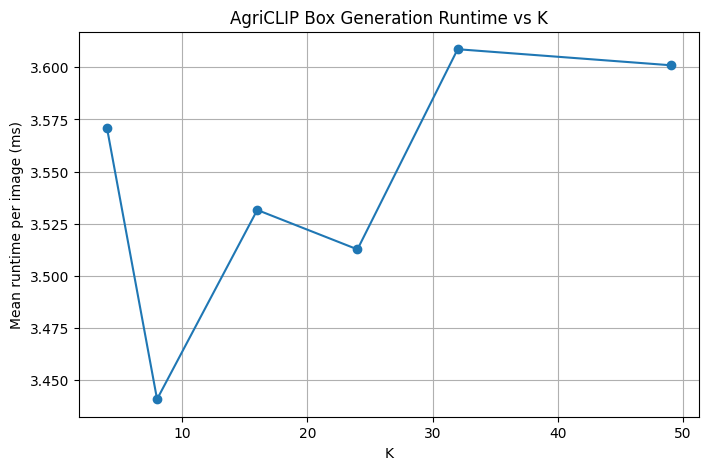

In [58]:
# ============================================================
# K vs RUNTIME
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    runtime_df["K"],
    runtime_df["mean_runtime_ms"],
    marker="o"
)

plt.xlabel("K")
plt.ylabel("Mean runtime per image (ms)")
plt.title("AgriCLIP Box Generation Runtime vs K")

plt.grid(True)

plt.show()

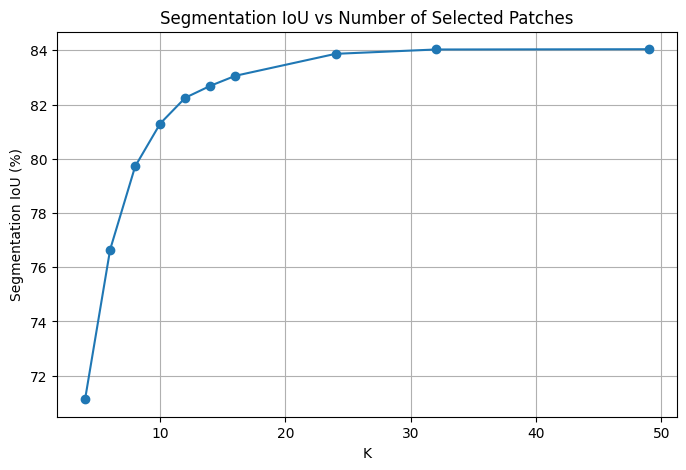

In [59]:
# ============================================================
# K vs IoU
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    k_iou_results["K"],
    k_iou_results["IoU"],
    marker="o"
)

plt.xlabel("K")
plt.ylabel("Segmentation IoU (%)")
plt.title("Segmentation IoU vs Number of Selected Patches")

plt.grid(True)

plt.show()

In [60]:
#Parameter counter 
def count_parameters(model):
    """Return total and trainable parameter counts."""
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(
        p.numel() for p in model.parameters()
        if p.requires_grad
    )
    
    return total_params, trainable_params


def format_params(num_params):
    """Format parameter count for readability."""
    if num_params >= 1e9:
        return f"{num_params / 1e9:.2f}B"
    elif num_params >= 1e6:
        return f"{num_params / 1e6:.2f}M"
    elif num_params >= 1e3:
        return f"{num_params / 1e3:.2f}K"
    else:
        return f"{num_params:,}"

In [61]:
#check SAM2 model 
sam2_total, sam2_trainable = count_parameters(sam2_model)

print("SAM2")
print("-" * 40)
print(f"Total parameters:     {sam2_total:,}")
print(f"Total parameters:     {format_params(sam2_total)}")
print(f"Trainable parameters: {sam2_trainable:,}")
print(f"Trainable parameters: {format_params(sam2_trainable)}")

SAM2
----------------------------------------
Total parameters:     31,440,721
Total parameters:     31.44M
Trainable parameters: 31,440,721
Trainable parameters: 31.44M


In [62]:
print(type(aligner))
print(aligner.__dict__.keys())

<class 'LinearAligner.LinearAligner'>
dict_keys(['W', 'b'])


In [63]:
aligner_total = aligner.W.numel() + aligner.b.numel()

print("AgriCLIP / LinearAligner")
print("-" * 40)
print(f"W parameters: {aligner.W.numel():,}")
print(f"b parameters: {aligner.b.numel():,}")
print(f"Total parameters: {aligner_total:,}")
print(f"Total parameters: {format_params(aligner_total)}")

AgriCLIP / LinearAligner
----------------------------------------
W parameters: 1,048,576
b parameters: 512
Total parameters: 1,049,088
Total parameters: 1.05M


In [64]:
combined_total = sam2_total + aligner_total
combined_trainable = sam2_trainable + aligner_total

print("Full Pipeline: AgriCLIP/Aligner + SAM2")
print("-" * 50)
print(f"Total parameters:     {combined_total:,}")
print(f"Total parameters:     {format_params(combined_total)}")
print(f"Trainable parameters: {combined_trainable:,}")
print(f"Trainable parameters: {format_params(combined_trainable)}")

Full Pipeline: AgriCLIP/Aligner + SAM2
--------------------------------------------------
Total parameters:     32,489,809
Total parameters:     32.49M
Trainable parameters: 32,489,809
Trainable parameters: 32.49M


In [65]:
print("Variables related to CLIP / AgriCLIP:")
for name in dir():
    if any(x in name.lower() for x in ["clip", "agri", "encoder", "model"]):
        print(name)

Variables related to CLIP / AgriCLIP:
AGRICLIP_ROOT
MODEL_NAME
Sam2Model
agriclip_box
benchmark_agriclip_box
dino_model
generate_agriclip_box
sam2_model


In [66]:
print("agriclip_box:")
print(type(agriclip_box))

print("\nbenchmark_agriclip_box:")
print(type(benchmark_agriclip_box))

print("\ndino_model:")
print(type(dino_model))

print("\ngenerate_agriclip_box:")
print(type(generate_agriclip_box))

agriclip_box:
<class 'numpy.ndarray'>

benchmark_agriclip_box:
<class 'function'>

dino_model:
<class 'torchvision.models.resnet.ResNet'>

generate_agriclip_box:
<class 'function'>


In [67]:
print("DINO model type:")
print(type(dino_model))

if hasattr(dino_model, "parameters"):
    total, trainable = count_parameters(dino_model)

    print("\nDINO / AgriCLIP feature model")
    print("-" * 45)
    print(f"Total parameters:     {total:,}")
    print(f"Total parameters:     {format_params(total)}")
    print(f"Trainable parameters: {trainable:,}")
    print(f"Trainable parameters: {format_params(trainable)}")
else:
    print("This object does not expose PyTorch parameters.")

DINO model type:
<class 'torchvision.models.resnet.ResNet'>

DINO / AgriCLIP feature model
---------------------------------------------
Total parameters:     23,508,032
Total parameters:     23.51M
Trainable parameters: 0
Trainable parameters: 0


In [68]:
import inspect

print("agriclip_box type:")
print(type(agriclip_box))

if callable(agriclip_box):
    print("\nFunction signature:")
    print(inspect.signature(agriclip_box))

agriclip_box type:
<class 'numpy.ndarray'>


In [69]:
# DINO / AgriCLIP parameters
dino_total, dino_trainable = count_parameters(dino_model)

# LinearAligner parameters
aligner_total = aligner.W.numel() + aligner.b.numel()

# Check whether W and b are trainable
aligner_trainable = 0

if getattr(aligner.W, "requires_grad", False):
    aligner_trainable += aligner.W.numel()

if getattr(aligner.b, "requires_grad", False):
    aligner_trainable += aligner.b.numel()

# SAM2 parameters
sam2_total, sam2_trainable = count_parameters(sam2_model)

# Full pipeline
full_total = dino_total + aligner_total + sam2_total
full_trainable = (
    dino_trainable
    + aligner_trainable
    + sam2_trainable
)

print("=" * 60)
print("COMPUTATIONAL COST — PARAMETER SUMMARY")
print("=" * 60)

print("\nDINO / AgriCLIP encoder:")
print(f"  Total:      {dino_total:,} ({format_params(dino_total)})")
print(f"  Trainable:  {dino_trainable:,} ({format_params(dino_trainable)})")

print("\nLinearAligner:")
print(f"  Total:      {aligner_total:,} ({format_params(aligner_total)})")
print(f"  Trainable:  {aligner_trainable:,} ({format_params(aligner_trainable)})")

print("\nSAM2:")
print(f"  Total:      {sam2_total:,} ({format_params(sam2_total)})")
print(f"  Trainable:  {sam2_trainable:,} ({format_params(sam2_trainable)})")

print("\n" + "-" * 60)

print("\nFULL PIPELINE:")
print(f"  Total:      {full_total:,} ({format_params(full_total)})")
print(f"  Trainable:  {full_trainable:,} ({format_params(full_trainable)})")

COMPUTATIONAL COST — PARAMETER SUMMARY

DINO / AgriCLIP encoder:
  Total:      23,508,032 (23.51M)
  Trainable:  0 (0)

LinearAligner:
  Total:      1,049,088 (1.05M)
  Trainable:  0 (0)

SAM2:
  Total:      31,440,721 (31.44M)
  Trainable:  31,440,721 (31.44M)

------------------------------------------------------------

FULL PIPELINE:
  Total:      55,997,841 (56.00M)
  Trainable:  31,440,721 (31.44M)


In [70]:
#GPU memory 
import torch
import gc
import time


def reset_gpu_memory():
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()


def get_gpu_memory_stats():
    return {
        "current_allocated_GB":
            torch.cuda.memory_allocated() / (1024 ** 3),

        "current_reserved_GB":
            torch.cuda.memory_reserved() / (1024 ** 3),

        "peak_allocated_GB":
            torch.cuda.max_memory_allocated() / (1024 ** 3),

        "peak_reserved_GB":
            torch.cuda.max_memory_reserved() / (1024 ** 3),
    }

In [71]:
print("DINO device:")
print(next(dino_model.parameters()).device)

print("\nSAM2 device:")
print(next(sam2_model.parameters()).device)

print("\nAligner:")
print("W:", aligner.W.device if hasattr(aligner.W, "device") else "no device")
print("b:", aligner.b.device if hasattr(aligner.b, "device") else "no device")

DINO device:
cuda:0

SAM2 device:
cuda:0

Aligner:
W: cuda:0
b: cuda:0


In [72]:
import time
import gc
import torch
import numpy as np
import pandas as pd
from tqdm import tqdm

BENCHMARK_IMAGES = len(val_hf)
TOP_K = 32

print(f"Benchmark images: {BENCHMARK_IMAGES}")
print(f"Top-K: {TOP_K}")
print(f"GPU: {torch.cuda.get_device_name(0)}")

Benchmark images: 755
Top-K: 32
GPU: NVIDIA GeForce RTX 4090


In [73]:
#timing + GPU memory helper 
def reset_gpu_benchmark():
    """
    Clear cached GPU memory and reset peak-memory statistics.
    """
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    torch.cuda.synchronize()


def get_gpu_memory():
    """
    Return GPU memory statistics in GB.
    """
    return {
        "current_allocated_GB":
            torch.cuda.memory_allocated() / (1024 ** 3),

        "current_reserved_GB":
            torch.cuda.memory_reserved() / (1024 ** 3),

        "peak_allocated_GB":
            torch.cuda.max_memory_allocated() / (1024 ** 3),

        "peak_reserved_GB":
            torch.cuda.max_memory_reserved() / (1024 ** 3),
    }

In [74]:
#generate and store boxes for calculations 
benchmark_data = []

print("Generating AgriCLIP boxes for all validation images...")

for idx in tqdm(
    range(BENCHMARK_IMAGES),
    desc="Generating AgriCLIP boxes"
):

    image = get_image(idx, split=val_hf)

    box, boxes, scores, topk_indices = generate_agriclip_box(
        image,
        TOP_K
    )

    benchmark_data.append({
        "image_id": idx,
        "box": box,
    })

print(
    f"\nStored {len(benchmark_data)} "
    "AgriCLIP boxes."
)

Generating AgriCLIP boxes for all validation images...


Generating AgriCLIP boxes: 100%|██████████| 755/755 [00:07<00:00, 97.40it/s] 


Stored 755 AgriCLIP boxes.


In [75]:
print("Warming up DINO + Aligner...")

for item in benchmark_data[:5]:

    image = get_image(
        item["image_id"],
        split=val_hf
    )

    _ = generate_agriclip_box(
        image,
        TOP_K
    )

torch.cuda.synchronize()

print("Warm-up complete.")

Warming up DINO + Aligner...
Warm-up complete.


In [76]:
reset_gpu_benchmark()

times_agriclip = []

for item in tqdm(
    benchmark_data,
    desc="DINO + Aligner benchmark"
):

    image = get_image(
        item["image_id"],
        split=val_hf
    )
    benchmark_start = time.perf_counter()

    torch.cuda.synchronize()
    start = time.perf_counter()

    _ = generate_agriclip_box(
        image,
        TOP_K
    )

    torch.cuda.synchronize()
    end = time.perf_counter()

    times_agriclip.append(end - start)


agri_mean = np.mean(times_agriclip)
agri_std = np.std(times_agriclip)
agri_min = np.min(times_agriclip)
agri_max = np.max(times_agriclip)

agri_memory = get_gpu_memory()

print("\n" + "=" * 60)
print("DINO + LINEAR ALIGNER — FULL VALIDATION")
print("=" * 60)

print(f"Images:              {len(times_agriclip)}")
print(f"Mean runtime:        {agri_mean * 1000:.4f} ms")
print(f"Std runtime:         {agri_std * 1000:.4f} ms")
print(f"Min runtime:         {agri_min * 1000:.4f} ms")
print(f"Max runtime:         {agri_max * 1000:.4f} ms")
print(f"Images/sec:          {1 / agri_mean:.2f}")

print("\nGPU Memory:")
print(f"Current allocated:   {agri_memory['current_allocated_GB']:.3f} GB")
print(f"Current reserved:    {agri_memory['current_reserved_GB']:.3f} GB")
print(f"Peak allocated:      {agri_memory['peak_allocated_GB']:.3f} GB")
print(f"Peak reserved:       {agri_memory['peak_reserved_GB']:.3f} GB")

DINO + Aligner benchmark: 100%|██████████| 755/755 [00:07<00:00, 97.77it/s] 


DINO + LINEAR ALIGNER — FULL VALIDATION
Images:              755
Mean runtime:        3.6557 ms
Std runtime:         0.4324 ms
Min runtime:         3.3919 ms
Max runtime:         8.8245 ms
Images/sec:          273.54

GPU Memory:
Current allocated:   0.691 GB
Current reserved:    0.818 GB
Peak allocated:      0.701 GB
Peak reserved:       0.818 GB


In [77]:
print("Warming up SAM2...")

for item in benchmark_data[:5]:

    image = get_image(
        item["image_id"],
        split=val_hf
    )

    _ = sam2_predict_box(
        image,
        item["box"]
    )

torch.cuda.synchronize()

print("SAM2 warm-up complete.")

Warming up SAM2...


SAM2 warm-up complete.


In [78]:
#SAM2 computational cost 
reset_gpu_benchmark()

times_sam2 = []

for item in tqdm(
    benchmark_data,
    desc="SAM2 benchmark"
):

    image = get_image(
        item["image_id"],
        split=val_hf
    )

    box = item["box"]
    benchmark_start = time.perf_counter()
    torch.cuda.synchronize()
    start = time.perf_counter()

    _ = sam2_predict_box(
        image,
        box
    )

    torch.cuda.synchronize()
    end = time.perf_counter()

    times_sam2.append(end - start)


sam2_mean = np.mean(times_sam2)
sam2_std = np.std(times_sam2)
sam2_min = np.min(times_sam2)
sam2_max = np.max(times_sam2)

sam2_memory = get_gpu_memory()

print("\n" + "=" * 60)
print("SAM2 — FULL VALIDATION")
print("=" * 60)

print(f"Images:              {len(times_sam2)}")
print(f"Mean runtime:        {sam2_mean * 1000:.4f} ms")
print(f"Std runtime:         {sam2_std * 1000:.4f} ms")
print(f"Min runtime:         {sam2_min * 1000:.4f} ms")
print(f"Max runtime:         {sam2_max * 1000:.4f} ms")
print(f"Images/sec:          {1 / sam2_mean:.2f}")

print("\nGPU Memory:")
print(f"Current allocated:   {sam2_memory['current_allocated_GB']:.3f} GB")
print(f"Current reserved:    {sam2_memory['current_reserved_GB']:.3f} GB")
print(f"Peak allocated:      {sam2_memory['peak_allocated_GB']:.3f} GB")
print(f"Peak reserved:       {sam2_memory['peak_reserved_GB']:.3f} GB")

SAM2 benchmark: 100%|██████████| 755/755 [00:23<00:00, 32.31it/s]


SAM2 — FULL VALIDATION
Images:              755
Mean runtime:        24.2715 ms
Std runtime:         0.6465 ms
Min runtime:         23.8854 ms
Max runtime:         37.0774 ms
Images/sec:          41.20

GPU Memory:
Current allocated:   0.691 GB
Current reserved:    1.240 GB
Peak allocated:      0.989 GB
Peak reserved:       1.240 GB


In [79]:
print("Warming up full pipeline...")

for item in benchmark_data[:5]:

    image = get_image(
        item["image_id"],
        split=val_hf
    )

    box, _, _, _ = generate_agriclip_box(
        image,
        TOP_K
    )

    _ = sam2_predict_box(
        image,
        box
    )

torch.cuda.synchronize()

print("Full pipeline warm-up complete.")

Warming up full pipeline...


Full pipeline warm-up complete.


In [80]:
#FULL PIPELINE 
reset_gpu_benchmark()

times_full = []

for item in tqdm(
    benchmark_data,
    desc="Full pipeline benchmark"
):

    image = get_image(
        item["image_id"],
        split=val_hf
    )
    benchmark_start = time.perf_counter()
    torch.cuda.synchronize()
    start = time.perf_counter()

    # ---------------------------------
    # 1. AgriCLIP localization
    # ---------------------------------
    box, _, _, _ = generate_agriclip_box(
        image,
        TOP_K
    )

    # ---------------------------------
    # 2. SAM2 segmentation
    # ---------------------------------
    _ = sam2_predict_box(
        image,
        box
    )

    torch.cuda.synchronize()
    end = time.perf_counter()

    times_full.append(end - start)


full_mean = np.mean(times_full)
full_std = np.std(times_full)
full_min = np.min(times_full)
full_max = np.max(times_full)

full_memory = get_gpu_memory()

print("\n" + "=" * 60)
print("FULL PIPELINE — FULL VALIDATION")
print("=" * 60)

print(f"Images:              {len(times_full)}")
print(f"Mean runtime:        {full_mean * 1000:.4f} ms")
print(f"Std runtime:         {full_std * 1000:.4f} ms")
print(f"Min runtime:         {full_min * 1000:.4f} ms")
print(f"Max runtime:         {full_max * 1000:.4f} ms")
print(f"Images/sec:          {1 / full_mean:.2f}")

print("\nGPU Memory:")
print(f"Current allocated:   {full_memory['current_allocated_GB']:.3f} GB")
print(f"Current reserved:    {full_memory['current_reserved_GB']:.3f} GB")
print(f"Peak allocated:      {full_memory['peak_allocated_GB']:.3f} GB")
print(f"Peak reserved:       {full_memory['peak_reserved_GB']:.3f} GB")

Full pipeline benchmark:   1%|          | 9/755 [00:00<00:25, 28.83it/s]

Full pipeline benchmark: 100%|██████████| 755/755 [00:26<00:00, 28.42it/s]


FULL PIPELINE — FULL VALIDATION
Images:              755
Mean runtime:        28.3718 ms
Std runtime:         1.3639 ms
Min runtime:         27.5556 ms
Max runtime:         39.7991 ms
Images/sec:          35.25

GPU Memory:
Current allocated:   0.691 GB
Current reserved:    1.240 GB
Peak allocated:      0.989 GB
Peak reserved:       1.240 GB


In [81]:
#Final table 
computational_summary = pd.DataFrame([
    {
        "Configuration": "DINO + LinearAligner",
        "Parameters_M": dino_total / 1e6 + aligner_total / 1e6,
        "Trainable_M": dino_trainable / 1e6 + aligner_trainable / 1e6,
        "Mean_Runtime_ms": agri_mean * 1000,
        "Std_Runtime_ms": agri_std * 1000,
        "Images_per_sec": 1 / agri_mean,
        "Peak_GPU_GB": agri_memory["peak_allocated_GB"],
    },
    {
        "Configuration": "SAM2",
        "Parameters_M": sam2_total / 1e6,
        "Trainable_M": sam2_trainable / 1e6,
        "Mean_Runtime_ms": sam2_mean * 1000,
        "Std_Runtime_ms": sam2_std * 1000,
        "Images_per_sec": 1 / sam2_mean,
        "Peak_GPU_GB": sam2_memory["peak_allocated_GB"],
    },
    {
        "Configuration": "Full Pipeline",
        "Parameters_M": full_total / 1e6,
        "Trainable_M": full_trainable / 1e6,
        "Mean_Runtime_ms": full_mean * 1000,
        "Std_Runtime_ms": full_std * 1000,
        "Images_per_sec": 1 / full_mean,
        "Peak_GPU_GB": full_memory["peak_allocated_GB"],
    }
])

computational_summary.round(3)

,Configuration,Parameters_M,Trainable_M,Mean_Runtime_ms,Std_Runtime_ms,Images_per_sec,Peak_GPU_GB
0,DINO + LinearAligner,24.557,0.000,3.656,0.432,273.544,0.701
1,SAM2,31.441,31.441,24.272,0.647,41.201,0.989
2,Full Pipeline,55.998,31.441,28.372,1.364,35.246,0.989


# BOX QUALITY ANALYSIS


In [82]:
import numpy as np

def mask_to_bbox(mask):
    """
    Convert a binary segmentation mask into a bounding box.

    Returns:
        [xmin, ymin, xmax, ymax]
    """

    # Make sure mask is binary
    mask = np.asarray(mask)
    ys, xs = np.where(mask > 0)

    # No foreground pixels
    if len(xs) == 0 or len(ys) == 0:
        return None

    xmin = xs.min()
    ymin = ys.min()
    xmax = xs.max()
    ymax = ys.max()

    return np.array(
        [xmin, ymin, xmax, ymax],
        dtype=np.float32
    )

In [83]:
#calculate bounding ox IoU
def calculate_box_iou(box1, box2):
    """
    Calculate IoU between two bounding boxes.

    Box format:
        [xmin, ymin, xmax, ymax]
    """

    if box1 is None or box2 is None:
        return np.nan

    # Intersection coordinates
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    # Intersection area
    intersection_width = max(0, x2 - x1)
    intersection_height = max(0, y2 - y1)

    intersection_area = (
        intersection_width *
        intersection_height
    )

    # Areas
    area1 = max(0, box1[2] - box1[0]) * \
            max(0, box1[3] - box1[1])

    area2 = max(0, box2[2] - box2[0]) * \
            max(0, box2[3] - box2[1])

    union_area = area1 + area2 - intersection_area

    if union_area <= 0:
        return np.nan

    return intersection_area / union_area

In [84]:
#Testing the function 


image = get_image(0, split=val_hf)
gt_mask = get_mask(0, split=val_hf)

# Generate AgriCLIP box
agriclip_box, boxes, scores, topk_indices = generate_agriclip_box(
    image,
    top_k=32
)

# Generate GT bounding box
gt_box = mask_to_bbox(gt_mask)

# Calculate box IoU
box_iou = calculate_box_iou(
    agriclip_box,
    gt_box
)

print("AgriCLIP box:", agriclip_box)
print("GT box:", gt_box)
print(f"Box IoU: {box_iou:.4f}")

AgriCLIP box: [  0   0 511 511]
GT box: [  0.   0. 511. 511.]
Box IoU: 1.0000


In [85]:
from tqdm import tqdm
import pandas as pd

box_results = []

TOP_K = 32

for idx in tqdm(
    range(len(val_hf)),
    desc="Box Quality Analysis"
):

    image = get_image(idx, split=val_hf)
    gt_mask = get_mask(idx, split=val_hf)

    try:

        # ------------------------------------------------
        # AgriCLIP predicted box
        # ------------------------------------------------

        agriclip_box, boxes, scores, topk_indices = \
            generate_agriclip_box(
                image,
                top_k=TOP_K
            )

        # ------------------------------------------------
        # Ground-truth bounding box
        # ------------------------------------------------

        gt_box = mask_to_bbox(gt_mask)

        # ------------------------------------------------
        # Box IoU
        # ------------------------------------------------

        box_iou = calculate_box_iou(
            agriclip_box,
            gt_box
        )

        box_results.append({
            "image_id": idx,
            "box_iou": box_iou
        })

    except Exception as e:

        print(
            f"Failed at image {idx}: {e}"
        )

        raise e


box_results_df = pd.DataFrame(box_results)

print("\nFinished box-quality analysis.")
print(
    f"Images evaluated: {len(box_results_df)}"
)

Box Quality Analysis: 100%|██████████| 755/755 [00:13<00:00, 57.41it/s]


Finished box-quality analysis.
Images evaluated: 755


In [86]:
print("=" * 60)
print("AGRICLIP BOX QUALITY — K=32")
print("=" * 60)

print(
    f"Images evaluated: "
    f"{len(box_results_df)}"
)

print(
    f"Mean Box IoU:   "
    f"{box_results_df['box_iou'].mean():.4f}"
)

print(
    f"Median Box IoU: "
    f"{box_results_df['box_iou'].median():.4f}"
)

print(
    f"Std Box IoU:    "
    f"{box_results_df['box_iou'].std():.4f}"
)

print(
    f"Minimum Box IoU: "
    f"{box_results_df['box_iou'].min():.4f}"
)

print(
    f"Maximum Box IoU: "
    f"{box_results_df['box_iou'].max():.4f}"
)

print("=" * 60)

AGRICLIP BOX QUALITY — K=32
Images evaluated: 755
Mean Box IoU:   0.9476
Median Box IoU: 1.0000
Std Box IoU:    0.1545
Minimum Box IoU: 0.0206
Maximum Box IoU: 1.0000


In [87]:
combined_results_df = pd.merge(
    results_df,
    box_results_df,
    on="image_id",
    how="inner"
)

print(
    "Combined images:",
    len(combined_results_df)
)

combined_results_df.head()

Combined images: 755


,image_id,iou,dice,precision,recall,sam2_confidence,box_iou
0,0,0.902177,0.948573,0.947917,0.949230,0.952444,1.000000
1,1,0.977636,0.988691,0.981931,0.995546,0.971790,1.000000
2,2,0.806422,0.892839,0.860177,0.928080,0.912800,0.988258
3,3,0.773661,0.872389,0.950898,0.805855,0.926644,1.000000
4,4,0.891987,0.942910,0.928020,0.958287,0.953880,1.000000


In [88]:
correlation = combined_results_df[
    ["box_iou", "iou"]
].corr().iloc[0, 1]

print("=" * 60)
print("BOX QUALITY vs SAM2 SEGMENTATION")
print("=" * 60)

print(
    f"Correlation (Box IoU vs Mask IoU): "
    f"{correlation:.4f}"
)

print("=" * 60)

BOX QUALITY vs SAM2 SEGMENTATION
Correlation (Box IoU vs Mask IoU): 0.4235


In [89]:
def classify_box_quality(iou):

    if iou < 0.25:
        return "Poor (<0.25)"

    elif iou < 0.50:
        return "Low (0.25–0.50)"

    elif iou < 0.75:
        return "Good (0.50–0.75)"

    else:
        return "Excellent (≥0.75)"


combined_results_df["box_quality"] = \
    combined_results_df["box_iou"].apply(
        classify_box_quality
    )

print(
    combined_results_df[
        "box_quality"
    ].value_counts()
)

box_quality
Excellent (≥0.75)    693
Good (0.50–0.75)      34
Low (0.25–0.50)       19
Poor (<0.25)           9
Name: count, dtype: int64


In [90]:
#CALCULATE SEG IOU FOR EACH BOX QUALITY GROUP 
quality_summary = (
    combined_results_df
    .groupby("box_quality")
    .agg(
        images=("image_id", "count"),
        mean_box_iou=("box_iou", "mean"),
        mean_mask_iou=("iou", "mean"),
        mean_dice=("dice", "mean"),
        mean_precision=("precision", "mean"),
        mean_recall=("recall", "mean")
    )
)

print(
    quality_summary.round(4)
)

                   images  mean_box_iou  mean_mask_iou  mean_dice  \
box_quality                                                         
Excellent (≥0.75)     693        0.9900         0.8526     0.9100   
Good (0.50–0.75)       34        0.6146         0.7789     0.8674   
Low (0.25–0.50)        19        0.3915         0.7164     0.8229   
Poor (<0.25)            9        0.1545         0.3853     0.4879   

                   mean_precision  mean_recall  
box_quality                                     
Excellent (≥0.75)          0.9035       0.9239  
Good (0.50–0.75)           0.8176       0.9361  
Low (0.25–0.50)            0.7633       0.9226  
Poor (<0.25)               0.4003       0.8022  


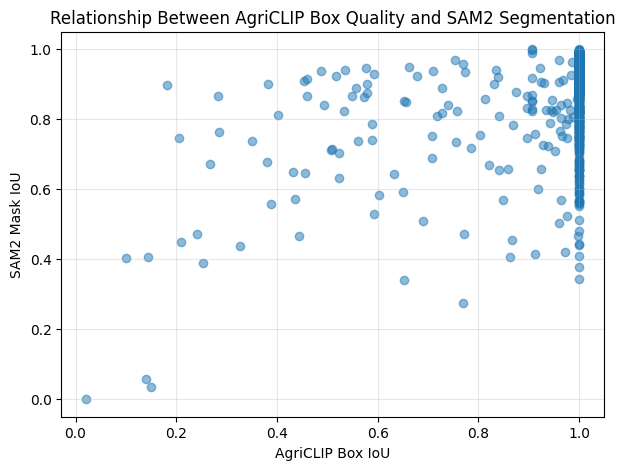

In [91]:
#pLOT bOX iOU VS SEG IOU 
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.scatter(
    combined_results_df["box_iou"],
    combined_results_df["iou"],
    alpha=0.5
)

plt.xlabel("AgriCLIP Box IoU")
plt.ylabel("SAM2 Mask IoU")
plt.title(
    "Relationship Between AgriCLIP Box Quality and SAM2 Segmentation"
)

plt.grid(True, alpha=0.3)

plt.show()

In [92]:
worst_boxes = (
    combined_results_df
    .sort_values(
        "box_iou",
        ascending=True
    )
    .head(10)
)

print(
    worst_boxes[
        [
            "image_id",
            "box_iou",
            "iou",
            "dice"
        ]
    ].to_string(index=False)
)

 image_id  box_iou      iou     dice
      369 0.020642 0.000198 0.000396
      748 0.099831 0.403818 0.575314
      207 0.139139 0.057219 0.108244
      227 0.143240 0.407025 0.578561
       93 0.149440 0.034453 0.066611
      593 0.181996 0.897931 0.946221
      292 0.205116 0.746266 0.854699
       60 0.210293 0.447764 0.618560
      535 0.240666 0.472833 0.642073
      729 0.252446 0.389654 0.560793


In [93]:
best_boxes = (
    combined_results_df
    .sort_values(
        "box_iou",
        ascending=False
    )
    .head(10)
)

print(
    best_boxes[
        [
            "image_id",
            "box_iou",
            "iou",
            "dice"
        ]
    ].to_string(index=False)
)

 image_id  box_iou      iou     dice
      754      1.0 0.943522 0.970941
        0      1.0 0.902177 0.948573
        1      1.0 0.977636 0.988691
      753      1.0 0.935898 0.966888
        3      1.0 0.773661 0.872389
        4      1.0 0.891987 0.942910
        5      1.0 0.793842 0.885075
        6      1.0 0.905144 0.950211
        7      1.0 0.954897 0.976928
      737      1.0 0.801745 0.889965


In [94]:
#gOOD BOX but bad seg
good_box_bad_mask = combined_results_df[
    (combined_results_df["box_iou"] >= 0.75) &
    (combined_results_df["iou"] < 0.60)
].sort_values(
    "iou",
    ascending=True
)

print(
    f"Images with good boxes but poor masks: "
    f"{len(good_box_bad_mask)}"
)

print(
    good_box_bad_mask[
        [
            "image_id",
            "box_iou",
            "iou",
            "dice"
        ]
    ].head(20).to_string(index=False)
)

Images with good boxes but poor masks: 30
 image_id  box_iou      iou     dice
      471 0.769080 0.274857 0.431197
      239 1.000000 0.344672 0.512649
      679 1.000000 0.378780 0.549443
      616 0.863014 0.405220 0.576735
      328 1.000000 0.407758 0.579301
      290 0.911937 0.413808 0.585380
      591 0.972729 0.420917 0.592458
      744 1.000000 0.440061 0.611170
      743 1.000000 0.444465 0.615404
      296 0.866091 0.456121 0.626488
       34 0.998043 0.466559 0.636264
      474 0.771037 0.472290 0.641572
      427 1.000000 0.481702 0.650201
      529 0.960861 0.503057 0.669378
      126 1.000000 0.512008 0.677256
      353 0.976517 0.524224 0.687857
      624 1.000000 0.551612 0.711018
       85 1.000000 0.558734 0.716907
      569 1.000000 0.559175 0.717270
      626 1.000000 0.563143 0.720526


In [95]:
#bad box bad mask 
bad_box_bad_mask = combined_results_df[
    (combined_results_df["box_iou"] < 0.50) &
    (combined_results_df["iou"] < 0.60)
].sort_values(
    "box_iou"
)

print(
    f"Images with poor boxes and poor masks: "
    f"{len(bad_box_bad_mask)}"
)

print(
    bad_box_bad_mask[
        [
            "image_id",
            "box_iou",
            "iou",
            "dice"
        ]
    ].head(20).to_string(index=False)
)

Images with poor boxes and poor masks: 12
 image_id  box_iou      iou     dice
      369 0.020642 0.000198 0.000396
      748 0.099831 0.403818 0.575314
      207 0.139139 0.057219 0.108244
      227 0.143240 0.407025 0.578561
       93 0.149440 0.034453 0.066611
       60 0.210293 0.447764 0.618560
      535 0.240666 0.472833 0.642073
      729 0.252446 0.389654 0.560793
      537 0.326477 0.437974 0.609155
      419 0.387234 0.557115 0.715573
       43 0.436399 0.572575 0.728201
       69 0.442783 0.465292 0.635085


In [96]:
#Save results 
combined_results_df.to_csv(
    "VegAnn_K32_box_quality_analysis.csv",
    index=False
)

print(
    "Saved: VegAnn_K32_box_quality_analysis.csv"
)

Saved: VegAnn_K32_box_quality_analysis.csv


In [97]:
# ============================================================
# SELECT FAILURE AND SUCCESS CASES
# ============================================================

# Good box but poor segmentation
failure_cases = (
    combined_results_df[
        (combined_results_df["box_iou"] >= 0.75) &
        (combined_results_df["iou"] < 0.60)
    ]
    .sort_values("iou", ascending=True)
    .head(6)
)

# Very good segmentation cases
success_cases = (
    combined_results_df[
        (combined_results_df["box_iou"] >= 0.75) &
        (combined_results_df["iou"] >= 0.90)
    ]
    .sort_values("iou", ascending=False)
    .head(6)
)

print("Failure cases:")
print(
    failure_cases[
        ["image_id", "box_iou", "iou", "dice"]
    ].to_string(index=False)
)

print("\nSuccessful cases:")
print(
    success_cases[
        ["image_id", "box_iou", "iou", "dice"]
    ].to_string(index=False)
)

Failure cases:
 image_id  box_iou      iou     dice
      471 0.769080 0.274857 0.431197
      239 1.000000 0.344672 0.512649
      679 1.000000 0.378780 0.549443
      616 0.863014 0.405220 0.576735
      328 1.000000 0.407758 0.579301
      290 0.911937 0.413808 0.585380

Successful cases:
 image_id  box_iou      iou     dice
       52 1.000000 0.999409 0.999704
      234 0.906067 0.999065 0.999532
      246 1.000000 0.997318 0.998657
      219 0.906067 0.996785 0.998390
      432 1.000000 0.996226 0.998110
      157 1.000000 0.995899 0.997945


In [99]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

def visualize_case(image_id, title_prefix=""):
   

    # Load image and GT
    image = get_image(
        image_id,
        split=val_hf
    )

    gt_mask = get_mask(
        image_id,
        split=val_hf
    )

    # Generate AgriCLIP box
    agriclip_box, boxes, scores, topk_indices = \
        generate_agriclip_box(
            image,
            top_k=32
        )

    # Generate SAM2 prediction
    pred_mask, confidence = \
        sam2_predict_box(
            image,
            agriclip_box
        )

    # Get metrics
    row = combined_results_df[
        combined_results_df["image_id"] == image_id
    ].iloc[0]

    box_iou = row["box_iou"]
    mask_iou = row["iou"]
    dice = row["dice"]

    # --------------------------------------------------------
    # Plot
    # --------------------------------------------------------

    fig, axes = plt.subplots(
        1,
        4,
        figsize=(16, 4)
    )

    # Original image
    axes[0].imshow(image)
    axes[0].set_title(
        f"Original\nImage {image_id}"
    )
    axes[0].axis("off")

    # Ground truth
    axes[1].imshow(gt_mask, cmap="gray")
    axes[1].set_title("Ground Truth Mask")
    axes[1].axis("off")

    # Original + AgriCLIP box
    axes[2].imshow(image)

    xmin, ymin, xmax, ymax = agriclip_box

    rect = patches.Rectangle(
        (xmin, ymin),
        xmax - xmin,
        ymax - ymin,
        fill=False,
        linewidth=2
    )

    axes[2].add_patch(rect)

    axes[2].set_title(
        f"AgriCLIP Box\nIoU = {box_iou:.3f}"
    )
    axes[2].axis("off")

    # SAM2 prediction
    axes[3].imshow(pred_mask, cmap="gray")
    axes[3].set_title(
        f"SAM2 Prediction\nIoU = {mask_iou:.3f}"
    )
    axes[3].axis("off")

    fig.suptitle(
        f"{title_prefix} — Image {image_id} | "
        f"Box IoU: {box_iou:.3f} | "
        f"Mask IoU: {mask_iou:.3f} | "
        f"Dice: {dice:.3f}",
        fontsize=13
    )

    plt.tight_layout()
    plt.show()

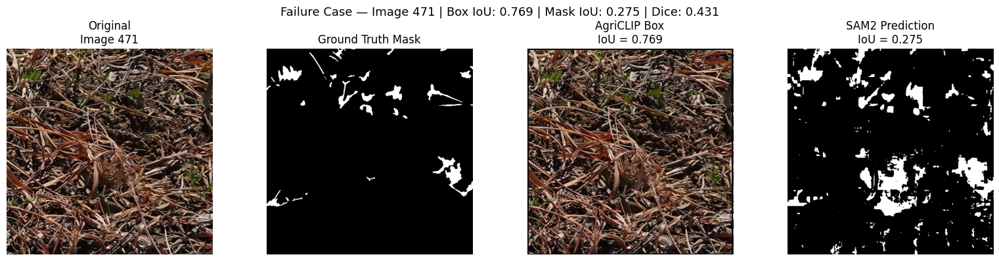

In [101]:
# Visualize the worst good-box / bad-mask case

failure_id = int(
    failure_cases.iloc[0]["image_id"]
)

visualize_case(
    failure_id,
    title_prefix="Failure Case"
)


In [102]:
def visualize_multiple_cases(
    dataframe,
    title_prefix="Failure Cases"
):
    """
    Visualize multiple cases.

    Each row:
        Original | GT Mask | AgriCLIP Box | SAM2 Mask
    """

    n = len(dataframe)

    fig, axes = plt.subplots(
        n,
        4,
        figsize=(14, 4 * n)
    )

    # Handle case where n = 1
    if n == 1:
        axes = np.expand_dims(
            axes,
            axis=0
        )

    for row_idx, (_, row) in enumerate(
        dataframe.iterrows()
    ):

        image_id = int(row["image_id"])

        image = get_image(
            image_id,
            split=val_hf
        )

        gt_mask = get_mask(
            image_id,
            split=val_hf
        )

        # Generate box
        agriclip_box, boxes, scores, topk_indices = \
            generate_agriclip_box(
                image,
                top_k=32
            )

        # Generate mask
        pred_mask, confidence = \
            sam2_predict_box(
                image,
                agriclip_box
            )

        box_iou = row["box_iou"]
        mask_iou = row["iou"]

        # ----------------------------------------------------
        # Original
        # ----------------------------------------------------

        axes[row_idx, 0].imshow(image)

        axes[row_idx, 0].set_title(
            f"Image {image_id}"
        )

        axes[row_idx, 0].axis("off")

        # ----------------------------------------------------
        # GT
        # ----------------------------------------------------

        axes[row_idx, 1].imshow(
            gt_mask,
            cmap="gray"
        )

        axes[row_idx, 1].set_title(
            "Ground Truth"
        )

        axes[row_idx, 1].axis("off")

        # ----------------------------------------------------
        # AgriCLIP box
        # ----------------------------------------------------

        axes[row_idx, 2].imshow(image)

        xmin, ymin, xmax, ymax = agriclip_box

        rect = patches.Rectangle(
            (xmin, ymin),
            xmax - xmin,
            ymax - ymin,
            fill=False,
            linewidth=2
        )

        axes[row_idx, 2].add_patch(rect)

        axes[row_idx, 2].set_title(
            f"AgriCLIP Box\n"
            f"Box IoU = {box_iou:.3f}"
        )

        axes[row_idx, 2].axis("off")

        # ----------------------------------------------------
        # SAM2 mask
        # ----------------------------------------------------

        axes[row_idx, 3].imshow(
            pred_mask,
            cmap="gray"
        )

        axes[row_idx, 3].set_title(
            f"SAM2 Prediction\n"
            f"Mask IoU = {mask_iou:.3f}"
        )

        axes[row_idx, 3].axis("off")

    fig.suptitle(
        title_prefix,
        fontsize=16
    )

    plt.tight_layout()
    plt.show()

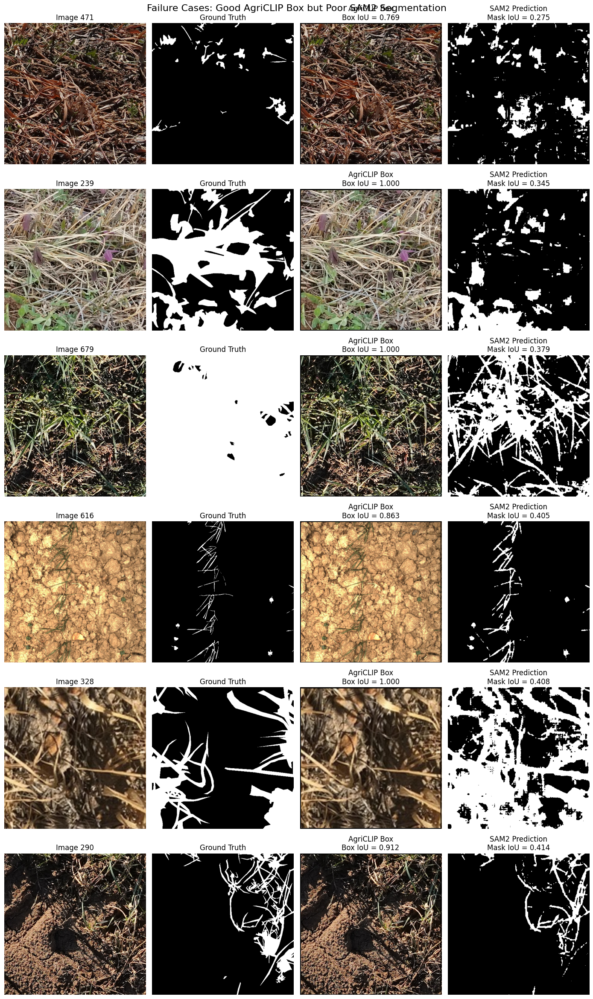

In [103]:
visualize_multiple_cases(
    failure_cases,
    title_prefix=(
        "Failure Cases: Good AgriCLIP Box "
        "but Poor SAM2 Segmentation"
    )
)

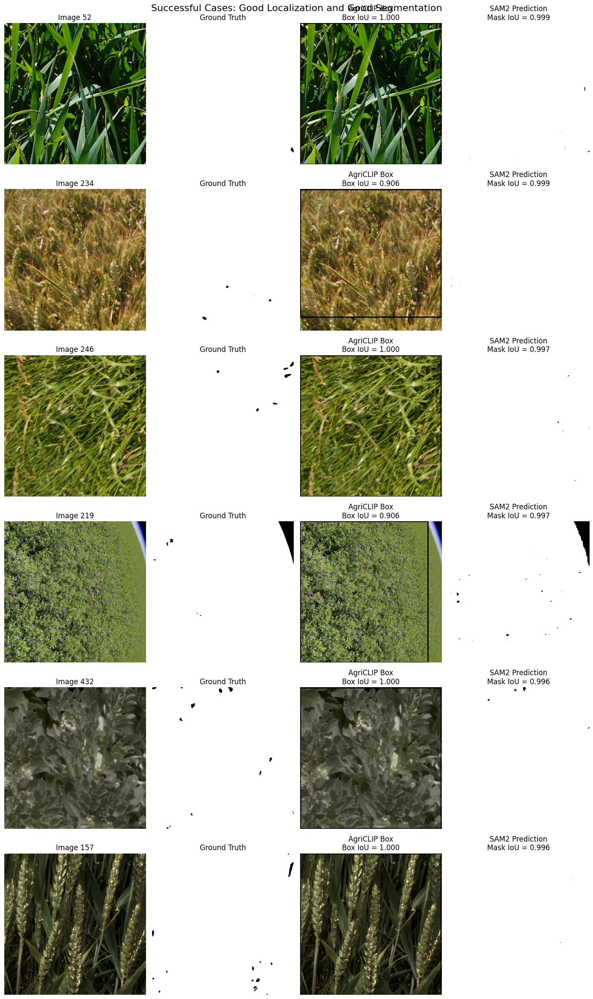

In [104]:
visualize_multiple_cases(
    success_cases,
    title_prefix=(
        "Successful Cases: Good Localization "
        "and Good Segmentation"
    )
)

In [105]:
def visualize_overlay(image_id):
    """
    Overlay GT mask, SAM2 mask and AgriCLIP box
    on the original image.
    """

    image = get_image(
        image_id,
        split=val_hf
    )

    gt_mask = get_mask(
        image_id,
        split=val_hf
    )

    agriclip_box, _, _, _ = \
        generate_agriclip_box(
            image,
            top_k=32
        )

    pred_mask, confidence = \
        sam2_predict_box(
            image,
            agriclip_box
        )

    row = combined_results_df[
        combined_results_df["image_id"] == image_id
    ].iloc[0]

    box_iou = row["box_iou"]
    mask_iou = row["iou"]

    fig, ax = plt.subplots(
        figsize=(7, 7)
    )

    ax.imshow(image)

    # GT contour
    ax.contour(
        gt_mask,
        levels=[0.5],
        linewidths=2
    )

    # Prediction contour
    ax.contour(
        pred_mask,
        levels=[0.5],
        linewidths=2
    )

    # AgriCLIP box
    xmin, ymin, xmax, ymax = agriclip_box

    rect = patches.Rectangle(
        (xmin, ymin),
        xmax - xmin,
        ymax - ymin,
        fill=False,
        linewidth=2
    )

    ax.add_patch(rect)

    ax.set_title(
        f"Image {image_id}\n"
        f"Box IoU = {box_iou:.3f} | "
        f"Mask IoU = {mask_iou:.3f}"
    )

    ax.axis("off")

    plt.tight_layout()
    plt.show()

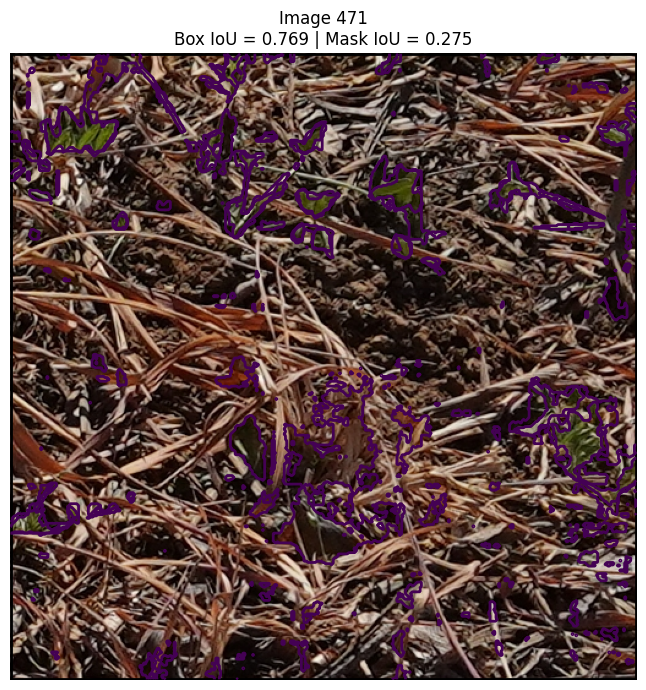

In [106]:
visualize_overlay(
    int(failure_cases.iloc[0]["image_id"])
)


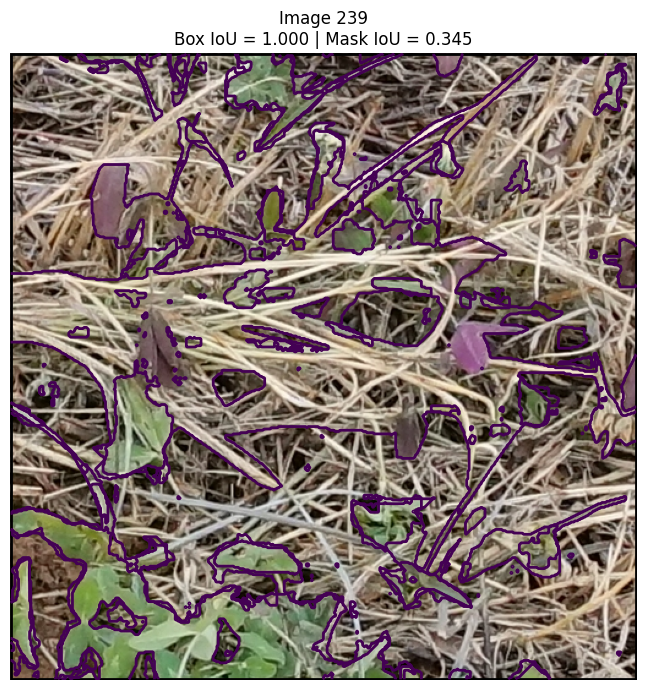

In [107]:
visualize_overlay(239)

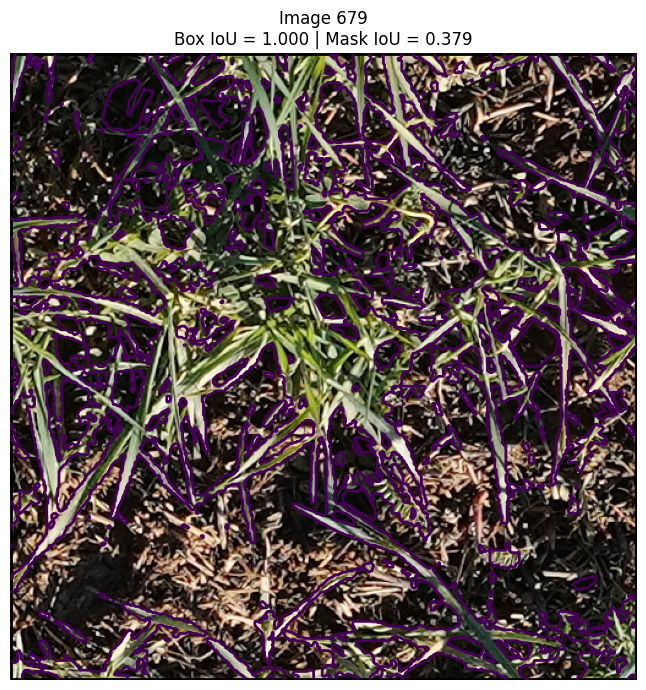

In [108]:
visualize_overlay(679)

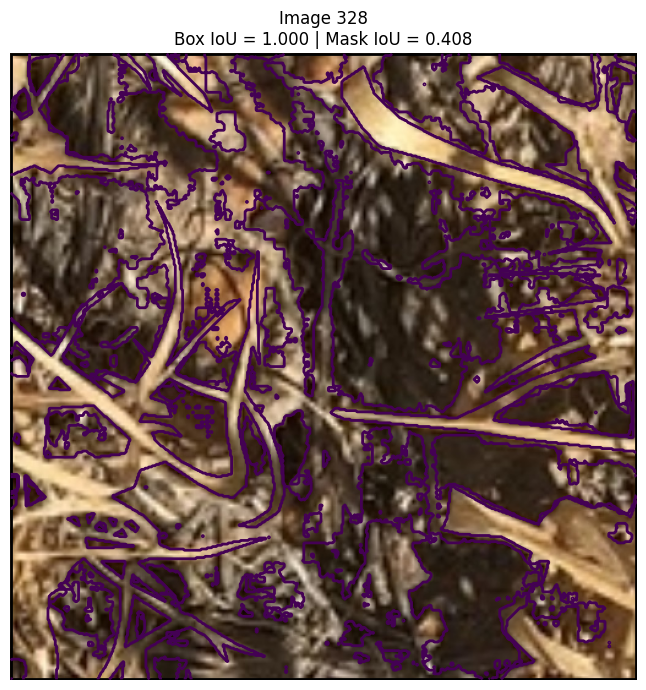

In [109]:
visualize_overlay(328)

In [110]:
failure_cases[
    [
        "image_id",
        "box_iou",
        "iou",
        "dice",
        "precision",
        "recall"
    ]
].to_csv(
    "VegAnn_K32_failure_cases.csv",
    index=False
)

success_cases[
    [
        "image_id",
        "box_iou",
        "iou",
        "dice",
        "precision",
        "recall"
    ]
].to_csv(
    "VegAnn_K32_success_cases.csv",
    index=False
)

print("Failure and success case lists saved.")

Failure and success case lists saved.
